# Polygenic Prediction and SNP Heritability in *Hypolimnas misippus*: PRS (B1 → B2) and GREML with GCTA

**Course:** *Genome-Wide Association Studies (GWAS) for Evolutionary Biology* (prstats.org)
**Topics:** (1) **polygenic risk scores (PRS)**: building a score from one study and testing how well it predicts a trait in another; (2) **SNP heritability** with **GCTA** (GREML), and the **missing heritability** problem.

This notebook **continues** the meta-analysis notebook (`Meta_Analysis_GWAS_GWAMA_METAL_Hypolimnas_misippus_Colab.ipynb`), which split the 20 butterflies into two batches **B1** and **B2** (10 butterflies each, 5 *m* and 5 *i* morphs), called variants with ANGSD in each batch, and tested association with the *m*/*i* wing-pattern morph. We reuse its files on Google Drive:

| File from the previous notebook | Used for |
|---|---|
| `summary_stats/sumstats_B1.txt`, `sumstats_B2.txt` | per-variant effect sizes (the **weights** of the PRS) |
| `angsd/calls_B1.beagle.gz` + `.mafs.gz`, `calls_B2...` | genotype likelihoods of the individuals of each batch (the **genotypes** to score) |
| `tables/batch_assignment.tsv`, `angsd/samples_B1.txt` ... | which butterfly is in which batch, and in which order |

### What you will do

**Part 1: a polygenic score, trained in B1 and tested in B2**

1. Read the B1 GWAS and choose **independent** variants (distance-based **clumping**).
2. Read the genotypes of the PRS variants in B1 and B2 (as **dosages** computed from ANGSD genotype likelihoods).
3. Build the score $\mathrm{PRS}_i=\sum_j \hat\beta_j\,x_{ij}$ with B1 effect sizes and apply it to the B2 butterflies.
4. **Evaluate the accuracy**: AUC with confidence intervals, accuracy, sensitivity and specificity, a **permutation test**, and the *in-sample* (B1) versus *out-of-sample* (B2) accuracy that exposes **overfitting**. We repeat the analysis with the number of variants K, and with a **biologically motivated** score that uses only the M-locus region.

**Part 2: heritability of the *m*/*i* morph with GCTA**

5. Call variants with ANGSD in **all 20 butterflies** jointly.
6. Build the **genetic relationship matrix (GRM)** from genotype dosages, write it in GCTA's format, and inspect it.
7. Run **GREML** (`gcta64 --reml`) to estimate the SNP heritability, on the observed and on the liability scale; partition the variance between the **M-locus chromosome** and the rest.
8. Check the result: cross-check the GRM with GCTA's own `--make-grm`, and **simulate phenotypes with a known heritability** to see how (un)precise GREML is with 20 butterflies.
9. Discuss the **missing heritability problem** and how GCTA can help to resolve it.

> **Honest framing (please read).** (i) Ten butterflies per batch is a *very* small training sample: a PRS needs hundreds to millions of individuals to work in practice, and a heritability estimate from 20 individuals has an enormous standard error. The goal is to learn the **workflow, the metrics and the pitfalls** on data you know well. (ii) The *m*/*i* morph is a **Mendelian-like trait controlled by a major locus** (the M locus on chromosome 26), not a highly polygenic trait, so the interesting "polygenic" lessons come from seeing what the genome-wide PRS does **not** capture compared with the locus-specific PRS. (iii) The previous notebook found **no variant that is genome-wide significant**; this is relevant for what to expect from a PRS built from its top hits.

## 0. Background

### 0.1 What is a polygenic risk score?

For most complex traits, **thousands of variants each contribute a tiny effect**. A **polygenic (risk) score** summarises an individual's genetic liability as a **weighted sum of the effect-allele counts** across many variants:

$$\mathrm{PRS}_i \;=\; \sum_{j=1}^{M}\hat\beta_j\;x_{ij},$$

where $x_{ij}\in[0,2]$ is the number (dosage) of effect alleles of individual $i$ at variant $j$, and $\hat\beta_j$ is the effect size of that allele estimated in a **training** GWAS (for a binary trait: the log odds ratio). The score is then evaluated in **independent test individuals** whose phenotype was not used to estimate the weights.

### 0.2 The classical recipe: clumping and thresholding (C+T)

| Step | What it does | Why |
|---|---|---|
| **Clumping** | keep the most significant variant in a region, drop its neighbours | neighbouring variants are in **linkage disequilibrium (LD)** and carry the same signal; adding all of them would count one association many times |
| **P-value thresholding** (or **top-K**) | keep variants with $P<P_T$ (or the K best clumps) | including more variants adds real signal but also noise: $P_T$ (or K) is a tuning parameter |
| **Weights** | the training effect sizes $\hat\beta_j$ | variants with larger effects count more |
| **Scoring** | $\sum_j\hat\beta_jx_{ij}$ in each test individual | the PRS |

Proper C+T clumps with **LD computed from a reference panel**. With only 10 training individuals LD cannot be estimated, so we clump by **physical distance** (`CLUMP_KB`), which is a common fallback.

### 0.3 How do we judge a PRS?

* **AUC (area under the ROC curve)**: the probability that a randomly chosen *m* butterfly has a higher score than a randomly chosen *i* butterfly. **0.5 = no better than chance, 1 = perfect.** (It equals the Mann-Whitney U statistic divided by $n_mn_i$.)
* **Accuracy, sensitivity, specificity** at a **fixed threshold chosen in the training set**.
* **$R^2$** (squared correlation between score and phenotype).
* **Out-of-sample versus in-sample.** The accuracy in the *training* batch is inflated because the weights were fitted to those very butterflies (**overfitting**). Only the **test** accuracy is honest.
* **A null distribution.** With 10 test butterflies even a useless score can reach AUC 0.7 by chance. A **permutation test** (shuffle the test labels many times) tells us which AUCs are compatible with chance.

### 0.4 Why PRS accuracy depends on the training sample size

Three forces limit a PRS: (i) the **heritability** of the trait ($h^2$): no score can explain more than the genetic part; (ii) the **number of independent variants** $M_e$ that influence the trait; (iii) the **size of the training sample** $N$, which sets how well the $\hat\beta_j$ are estimated. A widely used approximation (Daetwyler et al. 2008; Dudbridge 2013) for the expected squared correlation between the genetic prediction and the genetic value is

$$r^2\;\approx\;\frac{N\,h^2}{N\,h^2+M_e},$$

so a score trained on $N=10$ individuals will be almost pure noise unless the trait is determined by a **handful** of loci. There is also the **winner's curse**: the variants chosen because they have the smallest P-values in the training data have **over-estimated** effects, so their weights are biased upwards and the score does worse in new data than in the training data.

### 0.5 What to expect here

* The top variants of B1 were selected from millions of tests in 10 butterflies. Most will be chance associations: **their effects should not replicate in B2**, so the genome-wide PRS should be close to chance in B2 (AUC ≈ 0.5), while looking excellent in B1.
* The **M locus** is a real, strong association. If B1 tags it, a PRS restricted to the M-locus region has a chance of predicting B2.

### 0.6 Heritability: how much of the variation is genetic?

The **broad-sense heritability** $H^2=V_G/V_P$ is the fraction of phenotypic variance $V_P$ due to **all** genetic effects. The **narrow-sense heritability** $h^2=V_A/V_P$ counts only the **additive** part, which is what predicts the resemblance between parents and offspring and what responds to selection. Classical estimates come from **twin or pedigree** data: relatives share a known fraction of their genome, so the phenotypic resemblance of relatives estimates $h^2$.

**SNP heritability** $h^2_{SNP}$ is the fraction of phenotypic variance explained by the **additive effects of the genotyped SNPs**, estimated in **unrelated** individuals. The method is **GREML** (genomic-relatedness-based restricted maximum likelihood), implemented in **GCTA** (Yang, Lee, Goddard and **Visscher**, 2011).

### 0.7 The GREML model

GCTA fits a **linear mixed model** in which *all SNPs are random effects with a common variance*:

$$\mathbf y=\mathbf X\boldsymbol\beta+\mathbf g+\boldsymbol\varepsilon,\qquad \mathbf g\sim N(\mathbf 0,\mathbf A\,\sigma_g^2),\qquad \boldsymbol\varepsilon\sim N(\mathbf 0,\mathbf I\,\sigma_\varepsilon^2).$$

* $\mathbf y$: phenotype vector (here 0/1 for the *i*/*m* morph); $\mathbf X\boldsymbol\beta$: fixed effects (an intercept, optionally covariates);
* $\mathbf g$: the vector of **genetic values**; its covariance is the **genetic relationship matrix (GRM)** $\mathbf A$ times $\sigma_g^2$;
* $\mathbf A$ is estimated from the SNPs: for individuals $j,k$ and $N$ SNPs with allele frequency $p_i$,

$$A_{jk}=\frac1N\sum_{i=1}^{N}\frac{(x_{ij}-2p_i)(x_{ik}-2p_i)}{2p_i(1-p_i)}.$$

  Pairs that share more alleles than expected by chance have positive $A_{jk}$. Unrelated individuals have $A_{jk}\approx0$ and $A_{jj}\approx1$.
* **SNP heritability** is $h^2_{SNP}=\sigma_g^2/(\sigma_g^2+\sigma_\varepsilon^2)$, estimated by **REML**.

**The logic in one sentence:** if individuals who are *genetically more similar* (across all SNPs) are also *phenotypically more similar*, the SNPs explain part of the phenotypic variance. Notice that **no single SNP effect is ever estimated or tested**: the signal of thousands of tiny effects is pooled in $\sigma_g^2$.

**Binary traits and the liability scale.** For a 0/1 phenotype GCTA gives $h^2$ on the **observed 0/1 scale**, which depends on the proportion of cases in the sample. The **liability-scale** transformation (Lee et al. 2011) assumes an underlying continuous liability with a threshold, and needs the **population prevalence** $K$ of the trait (`--prevalence`) and the **proportion of cases in the sample** $P$.

**Assumptions to keep in mind.** (1) The individuals should be **unrelated** (cryptic relatedness inflates the estimate: GCTA's usual advice is to remove pairs with $A_{jk}>0.025$); (2) the SNPs should capture the causal variants through LD; (3) effects are additive and the effect sizes are independent of allele frequency and LD (the "GCTA model"); (4) the sample should be **large**: the standard error of $h^2_{SNP}$ is roughly $\propto 1/N$ and with thousands of individuals is still around 0.05 to 0.1.

### 0.8 The missing heritability problem

When the first GWAS appeared (about 2005 to 2009) a puzzle emerged. For human **height**, twin and family studies say $h^2\approx0.8$, yet the **genome-wide significant SNPs** of the first GWAS explained only **about 5 %** of the variance; for many diseases the gap was similar. This gap is the **missing heritability** (Maher 2008; Manolio et al. 2009). Explanations that were proposed:

| Explanation | Idea |
|---|---|
| **Many small effects below the significance threshold** | thousands of variants with tiny effects never reach $P<5\times10^{-8}$ but jointly explain a lot |
| **Incomplete LD (imperfect tagging)** | the causal variants (especially **rarer** ones) are only partly correlated with the genotyped SNPs |
| **Rare variants** | variants with MAF < 1 % are not on arrays and have low power in GWAS |
| **Non-additive effects and interactions** | twin heritability includes dominance and **epistasis** (Zuk et al. 2012: "phantom heritability"), which SNP additive models do not capture |
| **Overestimated family heritability** | shared environment and assortative mating can inflate twin/pedigree estimates |
| **Structural variants, imprecise phenotypes, gene-environment interaction** | additional, smaller contributions |

**How GCTA helps.** Instead of asking "which SNPs are significant?", GREML asks "how much variance do **all** the SNPs jointly explain?". Yang et al. (2010) applied it to height with ~300,000 common SNPs in ~4,000 unrelated people and found $h^2_{SNP}\approx0.45$, almost **ten times** what the significant SNPs explained: most of the "missing" heritability was **not missing, only hidden below the significance threshold** in many small effects. Extensions go further:

* **Variance partitioning** (`--mgrm`): one GRM per chromosome, per MAF bin or per annotation, to see *where* the variance lies (Yang et al. 2011 found height variance proportional to chromosome length, consistent with a highly polygenic architecture);
* **GREML-LDMS** (Yang et al. 2015; Evans et al. 2018): stratify by MAF and LD to get unbiased estimates when causal variants are rare or in unusual LD;
* **Whole-genome sequence data** (Wainschtein et al. 2022): including **rare variants** brought the estimate for height to about **0.68**, close to the pedigree value.

What GREML does **not** do: it does not identify the causal variants, it estimates **additive** variance only, and it remains unbiased only if its assumptions hold (LD- and MAF-dependent architectures can bias it). We return to this in Section 11.

### 0.9 The *m*/*i* morph as a heritability example

The *m*/*i* wing pattern is determined by **one major locus** (the M locus). A trait of this kind has a **high heritability** (close to 1 on the liability scale) that is concentrated in **one chromosome**. This is the opposite extreme from height, and it makes a good teaching contrast: the GREML estimate should be large, and the **chromosome partition** should put most of the variance on the M chromosome. With 20 butterflies the *precision* will be very poor; the simulations in Section 10 quantify this.

## 1. Install ANGSD, SAMtools, PLINK and GCTA

| Tool | What we use it for | How it is installed |
|---|---|---|
| **Conda** (Miniforge via `condacolab`) | installs everything below inside Colab | `pip install condacolab` |
| **ANGSD** | genotype likelihoods for all 20 butterflies (Part 2) | Bioconda |
| **SAMtools** | reading the BAM header | Bioconda |
| **PLINK 1.9** | converting best-guess genotypes to binary format for a GRM cross-check | Bioconda |
| **GCTA** (Yang, Lee, Goddard, Visscher) | GRM and GREML heritability estimation | Bioconda; fallback: the official binary from the Yang lab |

Run the next cell. **Colab restarts the runtime by itself when it finishes**; this is normal. After the restart continue with the cell after it (do *not* run the install cell again).

In [1]:
# Install Conda (Miniforge) inside Google Colab. The kernel restarts automatically afterwards.
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:19
🔁 Restarting kernel...


In [1]:
%%bash
# ANGSD, SAMtools and PLINK from Bioconda (+ conda-forge for the dependencies).
mamba install -y -q -c conda-forge -c bioconda angsd samtools htslib plink 2>&1 | tail -n 5

In [2]:
%%bash
# GCTA: try Bioconda first; if that fails download the official Linux binary from the Yang lab.
if ! command -v gcta64 >/dev/null 2>&1 && ! command -v gcta >/dev/null 2>&1; then
    mamba install -y -q -c conda-forge -c bioconda gcta 2>&1 | tail -n 3 || true
fi
if ! command -v gcta64 >/dev/null 2>&1 && ! command -v gcta >/dev/null 2>&1; then
    echo "Bioconda route failed: downloading the official GCTA binary."
    mkdir -p /content/gcta_bin && cd /content/gcta_bin
    wget -q https://yanglab.westlake.edu.cn/software/gcta/bin/gcta-1.94.1-linux-kernel-3-x86_64.zip -O gcta.zip && unzip -q -o gcta.zip
    exe=$(find /content/gcta_bin -type f -name 'gcta64*' ! -name '*.zip' | head -n 1)
    if [ -n "$exe" ]; then chmod +x "$exe"; ln -sf "$exe" /usr/local/bin/gcta64; fi
fi
command -v gcta64 || command -v gcta || echo "GCTA NOT FOUND"

/usr/local/bin/gcta64


In [3]:
%%bash
echo "ANGSD:    $(angsd 2>&1 | grep -i -m1 'version')"
echo "samtools: $(samtools --version | head -n 1)"
echo "PLINK:    $(plink --version 2>&1 | head -n 1)"
G=$(command -v gcta64 || command -v gcta)
echo "GCTA:     $G"
$G 2>&1 | grep -i -m2 "version\|GCTA" || true

ANGSD:    	-> angsd version: 0.940-dirty (htslib: 1.24) build(Dec 15 2024 09:11:59)
samtools: samtools 1.24
PLINK:    PLINK v1.9.0 64-bit (27 Sep 2026)
GCTA:     /usr/local/bin/gcta64
* Genome-wide Complex Trait Analysis (GCTA)
* version v1.94.1 Linux


> **What do the checks tell you?** You should see a version for ANGSD, SAMtools and PLINK, and a path for GCTA. If GCTA is missing, the notebook still runs Part 1 (PRS); Part 2 needs GCTA and stops with a clear message. GCTA prints a banner when called without arguments; that is normal.

## 2. Mount Google Drive and Locate the Results of the Meta-Analysis Notebook

Colab's local disk is wiped when the session ends, so inputs and outputs live on **Google Drive**. The next cell asks for permission to access your Drive.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 2.1 Parameters and folder search

Edit the parameters in the first block to change the analysis. The folder search finds the meta-analysis folder automatically; if it picks the wrong one, set `PROJECT_DIR_OVERRIDE`.

| Parameter | Meaning |
|---|---|
| `TRAIN`, `TEST` | the batch that provides the weights and the batch in which the score is evaluated |
| `K_LIST`, `K_MAIN` | numbers of clumped variants tried; `K_MAIN` is the value **declared in advance** for the headline result (never choose K by looking at the test accuracy) |
| `CLUMP_KB`, `CLUMP_POOL` | clumping distance and the number of best variants considered |
| `N_PERM`, `N_BOOT` | permutations and bootstrap replicates |
| `N_GRM_CHR` | number of chromosomes in the joint ANGSD run of Part 2 (the M chromosome plus the smallest autosomes, to keep the run short) |
| `PREVALENCE` | assumed population frequency of the *m* morph for the liability-scale transformation |

In [5]:
import os, re, json, gzip, glob, shutil, subprocess, time, math, struct
from bisect import bisect_left, insort
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

# ================================================================ PARAMETERS (edit here)
TRAIN, TEST = "B1", "B2"            # weights from TRAIN, accuracy measured in TEST
CASE_MORPH = "m"                    # coded 1 ("case"); the other morph is coded 0
K_LIST = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000]     # numbers of clumped variants in the score
K_MAIN = 100                        # the K we declare in advance as "the" PRS (do NOT tune it on the test batch)
CLUMP_KB = 250                      # clumping window (kb): keep one variant per window
CLUMP_POOL = 200_000                # clump among the best this many variants (clumping every variant would be slow)
MIN_IND_TEST = 4                    # a PRS variant must have genotype information in at least this many test individuals
M_LABEL = "26"                      # chromosome label of the M locus
PEAK_START, PEAK_END = 6_731_000, 6_743_400      # M-locus window used in the meta-analysis notebook
M_MAX_K = 20                        # number of clumped variants used in the M-locus score
M_CLUMP_KB = 2                      # clumping distance (kb) inside the small M-locus window
N_PERM, N_BOOT = 10_000, 2_000      # permutations / bootstrap replicates for the accuracy statistics
SEED = 2026
CHUNK = 200_000                     # rows read at a time from the big ANGSD files (lower it if Colab runs out of memory)
KEYMULT = 10**9                     # marker key = chromosome index * 1e9 + position (as in the meta-analysis notebook)

# ---- Part 2 (GCTA)
N_GRM_CHR = 6                       # chromosomes in the joint ANGSD run: the M chromosome + the smallest autosomes
GRM_CHR_LABELS = None               # or a list of chromosome labels, e.g. ["22", "24", "26"]; None = automatic choice
GRM_MIN_MAF = 0.05                  # variants used for the GRM: MAF (in the 20 butterflies) at least this
GRM_MAX_UNINFORMATIVE = 0.5         # ... and at most this fraction of the 20 butterflies without reads
PREVALENCE = 0.5                    # assumed population prevalence of the m morph (liability scale)
N_SIM, SIM_H2 = 100, [0.0, 0.5, 0.9]    # Section 10: phenotypes simulated per true heritability, and the true values
MIN_MAPQ, MIN_BASEQ, GL_MODEL, SNP_PVAL = 30, 20, 2, 1e-6      # ANGSD settings (as in the earlier notebooks)
FORCE = False                       # True = redo steps even if their output exists
THREADS = os.cpu_count() or 2

# If the automatic search fails, set the project folder (the one that contains 'bams') here, e.g.
# PROJECT_DIR_OVERRIDE = "/content/drive/MyDrive/GWAS"
PROJECT_DIR_OVERRIDE = None

# ================================================================ find the project folder on Google Drive
DRIVE_ROOT = Path("/content/drive/MyDrive")

def find_on_drive(name, kind, maxdepth=6):
    res = subprocess.run(["find", str(DRIVE_ROOT), "-maxdepth", str(maxdepth), "-type", kind, "-name", name], capture_output=True, text=True)
    return [Path(p) for p in res.stdout.splitlines() if p.strip()]

if PROJECT_DIR_OVERRIDE:
    PROJECT_DIR = Path(PROJECT_DIR_OVERRIDE)
else:
    hits = [p.parent for p in find_on_drive("metaanalysis_HypMis", "d") if (p / "summary_stats" / f"sumstats_{TRAIN}.txt").exists()]
    assert hits, ("Could not find 'metaanalysis_HypMis/summary_stats/sumstats_B1.txt' on your Google Drive. "
                  "Run the meta-analysis notebook first, or set PROJECT_DIR_OVERRIDE above.")
    if len(hits) > 1: print("WARNING: several matching project folders found, using the first one:", *hits, sep="\n    ")
    PROJECT_DIR = hits[0]
META = PROJECT_DIR / "metaanalysis_HypMis"
BAM_DIR = PROJECT_DIR / "bams"

OUT = PROJECT_DIR / "prs_gcta_HypMis"
D = {k: OUT / k for k in ["angsd", "tables", "figures", "gcta"]}
for d in D.values(): d.mkdir(parents=True, exist_ok=True)
GCTA = shutil.which("gcta64") or shutil.which("gcta")

print("Project folder  :", PROJECT_DIR)
print("Meta-analysis   :", META)
print("Output folder   :", OUT)
print("GCTA executable :", GCTA or "NOT FOUND (Part 2 needs it)")

Project folder  : /content/drive/MyDrive/GWAS
Meta-analysis   : /content/drive/MyDrive/GWAS/metaanalysis_HypMis
Output folder   : /content/drive/MyDrive/GWAS/prs_gcta_HypMis
GCTA executable : /usr/local/bin/gcta64


In [6]:
# Small helpers: run a shell command (log kept on Drive), skip finished steps, save a figure.
def run(cmd, log=None, check=True, show=12, quiet=False):
    if not quiet: print("$", cmd if len(cmd) < 600 else cmd[:600] + " ...")
    t0 = time.time()
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, executable="/bin/bash")
    text = (r.stdout or "") + (r.stderr or "")
    if log is not None: Path(log).write_text(f"$ {cmd}\n\n{text}")
    if r.returncode != 0 and check:
        print(text[-3500:]); raise RuntimeError(f"Command failed with exit code {r.returncode} (see the output above).")
    if show and text.strip() and not quiet: print("\n".join(text.strip().splitlines()[-show:]))
    if not quiet: print(f"[done in {time.time() - t0:.1f} s, exit code {r.returncode}]")
    return r

def done(*paths):
    return (not FORCE) and all(Path(p).exists() and Path(p).stat().st_size > 0 for p in paths)

def savefig(name):
    plt.savefig(D["figures"] / f"{name}.png", dpi=150, bbox_inches="tight")

# PART 1: A Polygenic Score Trained in B1 and Tested in B2

## 3. Read the Data of the Two Batches

### 3.1 Who is in which batch, and the chromosome naming

The BEAGLE genotype files of the meta-analysis notebook list the individuals **in the order of the batch sample lists** (`angsd/samples_B1.txt`, `samples_B2.txt`). The phenotype files (`pheno_B1.ybin`, ...) hold the 0/1 coding of the morph (1 = *m*) in the same order. The marker keys in the summary-statistics files are `chromosome index × 10⁹ + position`, where the **chromosome index** is the position of the sequence in the BAM header; we rebuild this index from the header of one BAM file.

In [7]:
# ---- batch membership, sample order and phenotype (1 = m morph, 0 = i morph)
ba = pd.read_csv(META / "tables" / "batch_assignment.tsv", sep="\t")
SAMPLES, Y = {}, {}
for b in (TRAIN, TEST):
    ids = (META / "angsd" / f"samples_{b}.txt").read_text().split()
    y = np.array((META / "angsd" / f"pheno_{b}.ybin").read_text().split(), dtype=int)
    morph = ba.set_index("sampleID").loc[ids, "morph"].to_numpy()
    assert len(ids) == len(y), f"{b}: sample list and phenotype file have different lengths"
    if not ((morph == CASE_MORPH).astype(int) == y).all():
        print(f"WARNING: the phenotype file of {b} does not match CASE_MORPH = '{CASE_MORPH}'; using the file as the truth.")
    SAMPLES[b], Y[b] = ids, y
    print(f"{b}: {len(ids)} butterflies, {int(y.sum())} m morphs (1) and {int((1 - y).sum())} i morphs (0)")

# ---- chromosome index (BAM-header order) and chromosome labels (from the reference FASTA)
bam0 = BAM_DIR / f"{ba.sampleID.iloc[0]}.sorted.bam"
hdr = subprocess.run(["samtools", "view", "-H", str(bam0)], capture_output=True, text=True).stdout
sq = [l.split("\t") for l in hdr.splitlines() if l.startswith("@SQ")]
fai = pd.DataFrame({"contig": [x[1][3:] for x in sq], "length": [int(x[2][3:]) for x in sq]})
fasta = sorted((PROJECT_DIR / "reference_HypMis_v2").glob("*.fa")) if (PROJECT_DIR / "reference_HypMis_v2").exists() else []
label_of = {}
if fasta:
    for h in subprocess.run(["grep", ">", str(fasta[0])], capture_output=True, text=True).stdout.splitlines():
        name, _, desc = h[1:].partition(" ")
        m_ = re.search(r"(?:chromosome|scaffold)[:\s_]+([A-Za-z0-9]+)", desc)
        if m_: label_of[name] = m_.group(1)
fai["label"] = fai.contig.map(label_of)
CONTIG_INDEX = {c: i for i, c in enumerate(fai.contig)}
CONTIG_OF_LABEL = {lab: c for c, lab in zip(fai.contig, fai.label) if isinstance(lab, str)}
LABEL_OF_CI = np.array([l if isinstance(l, str) else "?" for l in fai.label])
M_CHROM = CONTIG_OF_LABEL.get(M_LABEL); assert M_CHROM, f"chromosome label {M_LABEL} not found: check the reference FASTA"
M_CI = CONTIG_INDEX[M_CHROM]
print(f"\n{len(fai)} sequences in the BAM header; M chromosome (label {M_LABEL}) = {M_CHROM} (index {M_CI})")

B1: 10 butterflies, 5 m morphs (1) and 5 i morphs (0)
B2: 10 butterflies, 5 m morphs (1) and 5 i morphs (0)

218 sequences in the BAM header; M chromosome (label 26) = JBBEEQ010000026.1 (index 137)


### 3.2 The training GWAS (B1) and the test-batch variant list (B2)

**Training weights.** `sumstats_B1.txt` has, for every variant tested in B1: marker key, effect allele (EA), other allele (NEA), effect size `BETA` (log odds of the *m* morph per copy of EA), `SE`, `P`, sample size and EA frequency. We read it into compact NumPy arrays (it has millions of rows).

**The score can only use variants that exist in the test batch.** B1 and B2 were called **separately**, so the lists of variants differ (the meta-analysis notebook showed that only about 2 of the 5 million tested variants of each batch are shared). A PRS is therefore built from the **intersection**: variants tested in B1, **called in B2** with genotype information in at least `MIN_IND_TEST` B2 butterflies, and with compatible alleles. This is also what one does in practice with a published PRS: variants missing in the target data are dropped.

In [8]:
ALLELE_CODE = {"A": 0, "C": 1, "G": 2, "T": 3}
ALLELE_LETTER = np.array(list("ACGTN"))

def read_sumstats(b):
    # Summary statistics of batch b -> compact arrays sorted by marker key.
    path = META / "summary_stats" / f"sumstats_{b}.txt"
    parts = {k: [] for k in ["key", "ea", "nea", "beta", "se", "p"]}
    for ch in pd.read_csv(path, sep="\t", usecols=["MARKERNAME", "EA", "NEA", "BETA", "SE", "P"], chunksize=CHUNK, dtype={"EA": str, "NEA": str}):
        parts["key"].append(np.rint(pd.to_numeric(ch.MARKERNAME, errors="coerce").to_numpy(np.float64)).astype(np.int64))
        parts["ea"].append(ch.EA.map(ALLELE_CODE).fillna(4).to_numpy(np.int8)); parts["nea"].append(ch.NEA.map(ALLELE_CODE).fillna(4).to_numpy(np.int8))
        parts["beta"].append(pd.to_numeric(ch.BETA, errors="coerce").to_numpy(np.float32)); parts["se"].append(pd.to_numeric(ch.SE, errors="coerce").to_numpy(np.float32))
        parts["p"].append(pd.to_numeric(ch.P, errors="coerce").to_numpy(np.float64))
    A = {k: np.concatenate(v) for k, v in parts.items()}
    ok = (A["key"] > 0) & (A["ea"] < 4) & (A["nea"] < 4) & np.isfinite(A["beta"]) & np.isfinite(A["se"]) & (A["se"] > 0) & (A["p"] > 0) & (A["p"] <= 1)
    A = {k: v[ok] for k, v in A.items()}
    o = np.argsort(A["key"], kind="stable"); A = {k: v[o] for k, v in A.items()}
    keep = np.concatenate([[True], A["key"][1:] != A["key"][:-1]])             # drop duplicated keys, if any
    return {k: v[keep] for k, v in A.items()}

def read_mafs(b):
    # Variant list of the ANGSD calls of batch b (alleles, frequency, number of individuals with data).
    parts = {k: [] for k in ["key", "major", "minor", "freq", "nind"]}
    for ch in pd.read_csv(META / "angsd" / f"calls_{b}.mafs.gz", sep="\t", chunksize=CHUNK, usecols=["chromo", "position", "major", "minor", "knownEM", "nInd"],
                          dtype={"chromo": str, "major": str, "minor": str}):
        ci = ch.chromo.map(CONTIG_INDEX); good = ci.notna().to_numpy()
        key = np.where(good, ci.fillna(0).to_numpy(np.int64) * KEYMULT + ch.position.to_numpy(np.int64), -1)
        parts["key"].append(key); parts["major"].append(ch.major.map(ALLELE_CODE).fillna(4).to_numpy(np.int8)); parts["minor"].append(ch.minor.map(ALLELE_CODE).fillna(4).to_numpy(np.int8))
        parts["freq"].append(pd.to_numeric(ch.knownEM, errors="coerce").to_numpy(np.float32)); parts["nind"].append(ch.nInd.to_numpy(np.int16))
    A = {k: np.concatenate(v) for k, v in parts.items()}
    keep = A["key"] > 0
    A = {k: v[keep] for k, v in A.items()}
    o = np.argsort(A["key"], kind="stable"); A = {k: v[o] for k, v in A.items()}
    keep = np.concatenate([[True], A["key"][1:] != A["key"][:-1]])
    return {k: v[keep] for k, v in A.items()}

S_TR = read_sumstats(TRAIN)
M_TE = read_mafs(TEST)
print(f"{TRAIN} GWAS: {len(S_TR['key']):,} variants with a valid effect size")
print(f"{TEST} calls: {len(M_TE['key']):,} variants (ANGSD SNP calls), {int((M_TE['nind'] >= MIN_IND_TEST).sum()):,} with data in >= {MIN_IND_TEST} individuals")

B1 GWAS: 2,133,575 variants with a valid effect size
B2 calls: 9,679,353 variants (ANGSD SNP calls), 8,947,307 with data in >= 4 individuals


In [9]:
# ---- the candidate variants: tested in TRAIN, called in TEST (>= MIN_IND_TEST individuals), compatible alleles
ok_te = M_TE["nind"] >= MIN_IND_TEST
common, i_s, i_m = np.intersect1d(S_TR["key"], M_TE["key"][ok_te], return_indices=True)
i_m = np.flatnonzero(ok_te)[i_m]
ea, nea = S_TR["ea"][i_s], S_TR["nea"][i_s]; mj, mn = M_TE["major"][i_m], M_TE["minor"][i_m]
compat = ((ea == mj) & (nea == mn)) | ((ea == mn) & (nea == mj))
i_s, i_m, common = i_s[compat], i_m[compat], common[compat]
CAND = dict(key=common, ci=(common // KEYMULT).astype(np.int32), pos=(common % KEYMULT).astype(np.int64), ea=S_TR["ea"][i_s], nea=S_TR["nea"][i_s],
            beta=S_TR["beta"][i_s], se=S_TR["se"][i_s], p=S_TR["p"][i_s])
print(f"Candidate variants for the score (tested in {TRAIN}, called in {TEST}, compatible alleles): {len(common):,}")
print(f"Smallest {TRAIN} P-value among them: {CAND['p'].min():.2e}; Bonferroni threshold for {len(common):,} tests: {0.05 / len(common):.2e}")

Candidate variants for the score (tested in B1, called in B2, compatible alleles): 1,956,335
Smallest B1 P-value among them: 1.62e-03; Bonferroni threshold for 1,956,335 tests: 2.56e-08


## 4. Clumping: One Variant per Region

### 4.1 Why and how

Ranking variants by P-value puts **neighbours of the same signal** next to each other. Clumping walks down the ranked list: the best variant is **kept**, every other variant within `CLUMP_KB` kb of it is **discarded**, then the next best remaining variant is kept, and so on. In a real analysis the discarded variants are those in **LD** ($r^2$ above a threshold) with a kept one; we use **physical distance** because LD cannot be estimated from 10 individuals.

We run the greedy algorithm on the `CLUMP_POOL` best variants (clumping all millions would be slow and unnecessary: the score only uses the top few thousand clumps) and keep up to `max(K_LIST)` clumps. We also build the list for the **M-locus window** (chromosome 26, positions `PEAK_START` to `PEAK_END`), clumped at a much finer scale (`M_CLUMP_KB`).

In [10]:
def clump(ci, pos, p, window_bp, max_keep, pool=None):
    # Greedy distance-based clumping. Returns indices (into the arrays) of the kept variants in order of significance.
    order = np.argsort(p, kind="stable")
    if pool: order = order[:pool]
    taken, kept = {}, []                                    # taken[chromosome] = sorted list of kept positions
    for i in order:
        lst = taken.setdefault(int(ci[i]), []); k = bisect_left(lst, int(pos[i]))
        near = (k < len(lst) and lst[k] - pos[i] <= window_bp) or (k > 0 and pos[i] - lst[k - 1] <= window_bp)
        if not near:
            insort(lst, int(pos[i])); kept.append(i)
            if len(kept) >= max_keep: break
    return np.array(kept, dtype=np.int64)

in_M = (CAND["ci"] == M_CI) & (CAND["pos"] >= PEAK_START) & (CAND["pos"] <= PEAK_END)
GW  = clump(CAND["ci"], CAND["pos"], CAND["p"], CLUMP_KB * 1000, max(K_LIST), CLUMP_POOL)                       # genome-wide list
GWX = GW[~in_M[GW]]                                                                                              # the same list without the M-locus window
MIDX = np.flatnonzero(in_M)
MLIST = MIDX[clump(CAND["ci"][MIDX], CAND["pos"][MIDX], CAND["p"][MIDX], M_CLUMP_KB * 1000, M_MAX_K)] if len(MIDX) else np.array([], dtype=np.int64)
print(f"genome-wide clumps (window {CLUMP_KB} kb): {len(GW):,}   of which in the M-locus window: {int(in_M[GW].sum())}")
print(f"variants in the M-locus window (chromosome {M_LABEL}, {PEAK_START:,}-{PEAK_END:,}) among the candidates: {len(MIDX):,}; clumps kept: {len(MLIST)}")

def cand_table(idx, n=10):
    t = pd.DataFrame({"chr": LABEL_OF_CI[CAND["ci"][idx]], "pos": CAND["pos"][idx], "EA": ALLELE_LETTER[CAND["ea"][idx]], "NEA": ALLELE_LETTER[CAND["nea"][idx]],
                      f"beta_{TRAIN}": CAND["beta"][idx], f"se_{TRAIN}": CAND["se"][idx], f"P_{TRAIN}": CAND["p"][idx]})
    return t.head(n).reset_index(drop=True)
print("\nBest genome-wide clumps (the first variants of the score):")
display(cand_table(GW, 10).style.format({f"beta_{TRAIN}": "{:.2f}", f"se_{TRAIN}": "{:.2f}", f"P_{TRAIN}": "{:.2e}"}))
if len(MLIST):
    print("Best variants of the M-locus window:"); display(cand_table(MLIST, 5).style.format({f"beta_{TRAIN}": "{:.2f}", f"se_{TRAIN}": "{:.2f}", f"P_{TRAIN}": "{:.2e}"}))

genome-wide clumps (window 250 kb): 1,302   of which in the M-locus window: 0
variants in the M-locus window (chromosome 26, 6,731,000-6,743,400) among the candidates: 46; clumps kept: 5

Best genome-wide clumps (the first variants of the score):


,chr,pos,EA,NEA,beta_B1,se_B1,P_B1
0,6,9080712,G,A,-6.03,1.91,1.62e-03
1,4,9349647,C,T,6.03,1.91,1.62e-03
2,24,15342654,C,T,-5.78,1.84,1.64e-03
3,23,6103446,T,A,5.80,1.84,1.64e-03
4,13,12469097,A,G,3.80,1.22,1.79e-03
5,19,14595241,G,C,4.99,1.60,1.80e-03
6,31,1577266,T,A,-3.27,1.05,1.81e-03
7,29,11482959,T,C,5.87,1.89,1.85e-03
8,16,13468795,C,T,5.87,1.89,1.85e-03
9,10,15022494,A,G,3.85,1.24,1.88e-03


Best variants of the M-locus window:


,chr,pos,EA,NEA,beta_B1,se_B1,P_B1
0,26,6742270,A,T,2.46,1.06,2.02e-02
1,26,6736512,A,G,-2.74,1.45,5.77e-02
2,26,6731747,G,A,-2.52,1.35,6.29e-02
3,26,6733900,A,G,3.40,2.42,1.59e-01
4,26,6739382,T,G,1.11,1.41,4.30e-01


## 5. Genotypes of the Score Variants in B1 and B2

### 5.1 From genotype likelihoods to dosages

The BEAGLE files hold, for each variant and individual, three **genotype likelihoods** (0, 1, 2 copies of the batch's minor allele). We turn them into **dosages** exactly as in the Mendelian-randomization notebook:

1. normalise the three likelihoods; 2. multiply by a **Hardy-Weinberg prior** from the allele frequency estimated by ANGSD in the batch; 3. normalise again (posterior genotype probabilities); 4. **dosage** $=P(1)+2P(2)$.

An individual without reads at a variant has a flat likelihood and receives the population-average dosage $2p$. Finally the dosage is **re-oriented to the effect allele** of the training GWAS: if the batch's minor allele is the effect allele the dosage is kept, otherwise it is replaced by $2-$dosage.

We read each BEAGLE file in chunks **in step with its `.mafs` file** (both come from the same ANGSD run and have the same row order), keep only the rows of the score variants, and cache the result on Google Drive.

In [11]:
def extract_dosage(b, keys, ea_codes):
    # Effect-allele dosages (variants x individuals) for the variants 'keys' in batch b; NaN where the variant is absent from the batch.
    n = len(SAMPLES[b]); order = np.argsort(keys); sk = keys[order]
    Dm = np.full((len(keys), n), np.nan, np.float32); unin = np.full(len(keys), np.nan, np.float32)
    rb = pd.read_csv(META / "angsd" / f"calls_{b}.beagle.gz", sep="\t", chunksize=CHUNK)
    rm = pd.read_csv(META / "angsd" / f"calls_{b}.mafs.gz", sep="\t", chunksize=CHUNK, usecols=["chromo", "position", "major", "minor", "knownEM"],
                     dtype={"chromo": str, "major": str, "minor": str})
    for cb, cm in zip(rb, rm):
        assert len(cb) == len(cm), "BEAGLE and MAFS files have different numbers of rows: they must come from the same ANGSD run"
        assert (cb.shape[1] - 3) // 3 == n, f"{b}: BEAGLE has {(cb.shape[1] - 3) // 3} individuals but the sample list has {n}"
        ci = cm.chromo.map(CONTIG_INDEX); good = ci.notna().to_numpy()
        kk = np.where(good, ci.fillna(0).to_numpy(np.int64) * KEYMULT + cm.position.to_numpy(np.int64), -1)
        j = np.minimum(np.searchsorted(sk, kk), len(sk) - 1); hit = sk[j] == kk
        if not hit.any(): continue
        rows = np.flatnonzero(hit); tgt = order[j[rows]]
        G = cb.iloc[rows, 3:].to_numpy(np.float64).reshape(len(rows), n, 3)
        flat = (G.max(-1) - G.min(-1)) < 1e-3                                       # no reads for this individual
        G = G / np.maximum(G.sum(-1, keepdims=True), 1e-300)                        # 1. normalise
        p = np.clip(np.nan_to_num(pd.to_numeric(cm.knownEM.iloc[rows], errors="coerce").to_numpy(np.float64), nan=0.5), 1e-6, 1 - 1e-6)
        post = G * np.stack([(1 - p) ** 2, 2 * p * (1 - p), p ** 2], 1)[:, None, :]  # 2. Hardy-Weinberg prior
        post /= post.sum(-1, keepdims=True)                                         # 3. posterior
        dose = post[..., 1] + 2 * post[..., 2]                                      # 4. dosage of the batch's minor allele
        minor = cm.minor.iloc[rows].map(ALLELE_CODE).fillna(4).to_numpy()
        dose = np.where((minor == ea_codes[tgt])[:, None], dose, 2 - dose)          # re-orient to the effect allele
        Dm[tgt] = dose.astype(np.float32); unin[tgt] = flat.mean(1)
    return Dm, unin

SEL = np.unique(np.concatenate([GW, MLIST]))                  # all variants that any score will need (indices into CAND), sorted
sel_keys = CAND["key"][SEL]
cache = D["tables"] / f"prs_dosages_{TRAIN}_{TEST}_K{max(K_LIST)}_w{CLUMP_KB}_pool{CLUMP_POOL}.npz"
if done(cache) and np.array_equal(np.load(cache)["keys"], sel_keys):
    z = np.load(cache); DOSE = {TRAIN: z["d_train"], TEST: z["d_test"]}; UNIN = {TRAIN: z["u_train"], TEST: z["u_test"]}
    print("dosages loaded from the cache:", cache.name)
else:
    DOSE, UNIN = {}, {}
    for b in (TRAIN, TEST):
        t0 = time.time(); DOSE[b], UNIN[b] = extract_dosage(b, sel_keys, CAND["ea"][SEL])
        print(f"[{b}] dosages of {len(SEL):,} variants read in {time.time() - t0:.0f} s")
    np.savez_compressed(cache, keys=sel_keys, d_train=DOSE[TRAIN], d_test=DOSE[TEST], u_train=UNIN[TRAIN], u_test=UNIN[TEST])
for b in (TRAIN, TEST):
    print(f"{b}: variants found in the BEAGLE file: {int(np.isfinite(DOSE[b][:, 0]).sum()):,} of {len(SEL):,};  "
          f"median fraction of individuals without reads: {np.nanmedian(UNIN[b]):.2f}")
POS_IN_SEL = {int(i): k for k, i in enumerate(SEL)}                                    # CAND index -> row of DOSE
def dosage_rows(idx, b):
    D_ = DOSE[b][[POS_IN_SEL[int(i)] for i in idx]].astype(np.float64)
    rowmean = np.nanmean(D_, axis=1, keepdims=True)
    return np.where(np.isnan(D_), np.where(np.isnan(rowmean), 0.0, rowmean), D_)       # a missing dosage is replaced by the variant's mean

[B1] dosages of 1,307 variants read in 103 s
[B2] dosages of 1,307 variants read in 96 s
B1: variants found in the BEAGLE file: 1,307 of 1,307;  median fraction of individuals without reads: 0.30
B2: variants found in the BEAGLE file: 1,307 of 1,307;  median fraction of individuals without reads: 0.40


## 6. Build the Score and Evaluate Its Accuracy

### 6.1 The metrics (implemented from scratch)

* **`auc(score, y)`**: the Mann-Whitney statistic: rank all individuals by score; AUC $=\big(\sum_{\text{m}}\mathrm{rank}-n_m(n_m+1)/2\big)/(n_mn_i)$.
* **Bootstrap 95 % CI**: resample the *m* and *i* butterflies with replacement (2000 times) and recompute the AUC. With 5 + 5 butterflies in a batch the interval is necessarily very wide.
* **Permutation P**: shuffle the labels of the test individuals `N_PERM` times; the P-value is the fraction of shuffles whose AUC is at least as large as the observed AUC. The 2.5 % and 97.5 % quantiles of the shuffled AUCs form the "chance band".
* **Classification at a training-derived threshold**: we classify a butterfly as *m* if its score exceeds the **midpoint of the two class means in the training batch** (never using test labels), and report accuracy, sensitivity, specificity and balanced accuracy.

In [12]:
rng = np.random.default_rng(SEED)

def auc(score, y):
    y = np.asarray(y); r = stats.rankdata(score); n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def auc_boot_ci(score, y, B=N_BOOT):
    pos, neg = score[y == 1], score[y == 0]
    ip = rng.integers(0, len(pos), (B, len(pos))); ineg = rng.integers(0, len(neg), (B, len(neg)))
    P_, N_ = pos[ip][:, :, None], neg[ineg][:, None, :]
    a = ((P_ > N_) + 0.5 * (P_ == N_)).mean((1, 2))
    return np.percentile(a, [2.5, 97.5])

def auc_perm(score, y, B=N_PERM):
    # permutation distribution of the AUC: random choices of which individuals are the m morphs
    n1 = int(np.sum(y)); n0 = len(y) - n1; r = stats.rankdata(score)
    pos_idx = np.array([rng.choice(len(y), n1, replace=False) for _ in range(B)])
    return (r[pos_idx].sum(1) - n1 * (n1 + 1) / 2) / (n1 * n0)

def classify(score_tr, y_tr, score_te, y_te):
    thr = 0.5 * (score_tr[y_tr == 1].mean() + score_tr[y_tr == 0].mean())              # midpoint of the training class means
    out = {}
    for nm, s, y in (("train", score_tr, y_tr), ("test", score_te, y_te)):
        pred = (s > thr).astype(int); tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
        sens, spec = tp / max(1, int((y == 1).sum())), tn / max(1, int((y == 0).sum()))
        out[nm] = dict(accuracy=(tp + tn) / len(y), sensitivity=sens, specificity=spec, balanced=(sens + spec) / 2, tp=tp, tn=tn)
    return thr, out

def roc_curve(score, y):
    o = np.argsort(-score, kind="stable"); ys = np.asarray(y)[o]; ss = score[o]
    tpr = np.concatenate([[0], np.cumsum(ys) / ys.sum()]); fpr = np.concatenate([[0], np.cumsum(1 - ys) / (1 - ys).sum()])
    last = np.concatenate([ss[1:] != ss[:-1], [True]])                                  # keep one point per distinct score (ties)
    return fpr[np.concatenate([[True], last])], tpr[np.concatenate([[True], last])]

def evaluate(idx, label, k_list):
    # PRS for the first K variants of the list 'idx' (CAND indices) for each K in k_list: accuracy in TRAIN (in-sample) and TEST.
    rows = []
    for K in k_list:
        if K > len(idx): continue
        sel = idx[:K]; w = CAND["beta"][sel].astype(np.float64)
        s_tr = (w[:, None] * dosage_rows(sel, TRAIN)).sum(0); s_te = (w[:, None] * dosage_rows(sel, TEST)).sum(0)
        a_tr, a_te = auc(s_tr, Y[TRAIN]), auc(s_te, Y[TEST]); lo, hi = auc_boot_ci(s_te, Y[TEST]); perm = auc_perm(s_te, Y[TEST])
        thr, cl = classify(s_tr, Y[TRAIN], s_te, Y[TEST])
        rows.append(dict(score=label, K=K, AUC_train=a_tr, AUC_test=a_te, test_CI_lo=lo, test_CI_hi=hi, perm_P=(1 + (perm >= a_te - 1e-12).sum()) / (1 + len(perm)),
                         null_lo=np.percentile(perm, 2.5), null_hi=np.percentile(perm, 97.5), acc_train=cl["train"]["accuracy"], acc_test=cl["test"]["accuracy"],
                         sens_test=cl["test"]["sensitivity"], spec_test=cl["test"]["specificity"], bal_acc_test=cl["test"]["balanced"],
                         R2_test=(np.corrcoef(s_te, Y[TEST])[0, 1] ** 2 if np.std(s_te) > 0 else np.nan)))
    return pd.DataFrame(rows)
print("metric functions defined")

metric functions defined


### 6.2 The genome-wide score: AUC as a function of the number of variants K

For each K in `K_LIST` the score uses the K best clumps of B1. Look at the **two AUC curves**:

* **In-sample (B1, training):** high and rising with K. The weights were fitted to these 10 butterflies, so any set of variants can separate them (overfitting).
* **Out-of-sample (B2, test):** the honest accuracy. The grey band is the range of AUCs expected **by chance** (95 % of label permutations): an observed AUC inside the band is **not distinguishable from a random score**.

,K,AUC_train,AUC_test,test_CI_lo,test_CI_hi,perm_P,null_lo,null_hi,acc_test,bal_acc_test,R2_test
0,1,1.000,0.200,0.000,0.540,0.953,0.120,0.880,0.300,0.300,0.272
1,2,1.000,0.280,0.000,0.680,0.887,0.120,0.880,0.300,0.300,0.202
2,5,1.000,0.560,0.200,1.000,0.420,0.160,0.880,0.600,0.600,0.029
3,10,1.000,0.640,0.240,1.000,0.274,0.120,0.880,0.600,0.600,0.061
4,20,1.000,0.680,0.320,1.000,0.207,0.120,0.880,0.500,0.500,0.062
5,50,1.000,0.640,0.240,1.000,0.282,0.120,0.880,0.400,0.400,0.026
6,100,1.000,0.600,0.240,1.000,0.346,0.120,0.880,0.500,0.500,0.002
7,200,1.000,0.880,0.600,1.000,0.028,0.120,0.880,0.500,0.500,0.359
8,500,1.000,0.400,0.000,0.760,0.722,0.120,0.880,0.500,0.500,0.004
9,1000,1.000,0.440,0.080,0.840,0.649,0.120,0.880,0.500,0.500,0.008


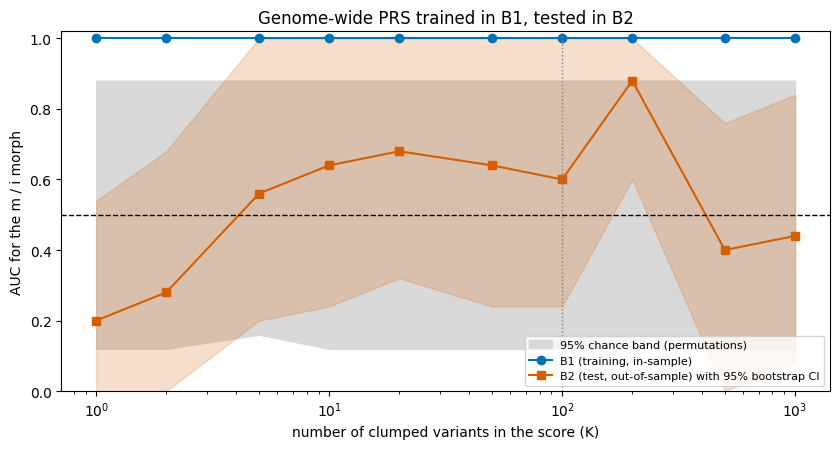

In [13]:
R_GW = evaluate(GW, "genome-wide", K_LIST)
pd.set_option("display.float_format", lambda v: f"{v:.3g}")
display(R_GW[["K", "AUC_train", "AUC_test", "test_CI_lo", "test_CI_hi", "perm_P", "null_lo", "null_hi", "acc_test", "bal_acc_test", "R2_test"]].style.format(precision=3))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.fill_between(R_GW.K, R_GW.null_lo, R_GW.null_hi, color="0.85", label="95% chance band (permutations)")
ax.fill_between(R_GW.K, R_GW.test_CI_lo, R_GW.test_CI_hi, color="#D55E00", alpha=0.2)
ax.plot(R_GW.K, R_GW.AUC_train, "o-", color="#0072B2", label=f"{TRAIN} (training, in-sample)")
ax.plot(R_GW.K, R_GW.AUC_test, "s-", color="#D55E00", label=f"{TEST} (test, out-of-sample) with 95% bootstrap CI")
ax.axhline(0.5, color="k", ls="--", lw=1); ax.axvline(K_MAIN, color="grey", ls=":", lw=1)
ax.set(xscale="log", ylim=(0, 1.02), xlabel="number of clumped variants in the score (K)", ylabel="AUC for the m / i morph",
       title=f"Genome-wide PRS trained in {TRAIN}, tested in {TEST}"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); savefig("prs_auc_vs_K"); plt.show()

**How to read this.** The in-sample AUC is close to 1 for almost any K, even though the variants are mostly noise: this is the **optimism of the training data**. The honest test AUC stays within (or near) the chance band. The *bootstrap CI* shows how little 10 test butterflies can tell us: with 5 *m* and 5 *i* morphs there are only 25 pairs to compare.

### 6.3 The declared score (K = `K_MAIN`): a closer look

We now examine the **one score we declared in advance**. (Choosing the best K from the table above using test performance would be **cheating**: it makes the test AUC optimistic, because we would be tuning on the test data. In real work K or $P_T$ is tuned in a separate validation sample, or by cross-validation within the training data.)

Three panels: the **score distribution by morph** in the training and test batches, the **ROC curves** (the AUC is the area under them), and the **per-variant replication** (the training weight against the effect observed in the test batch, from `sumstats_B2.txt`): if the variants were true associations the points would line up along the diagonal.

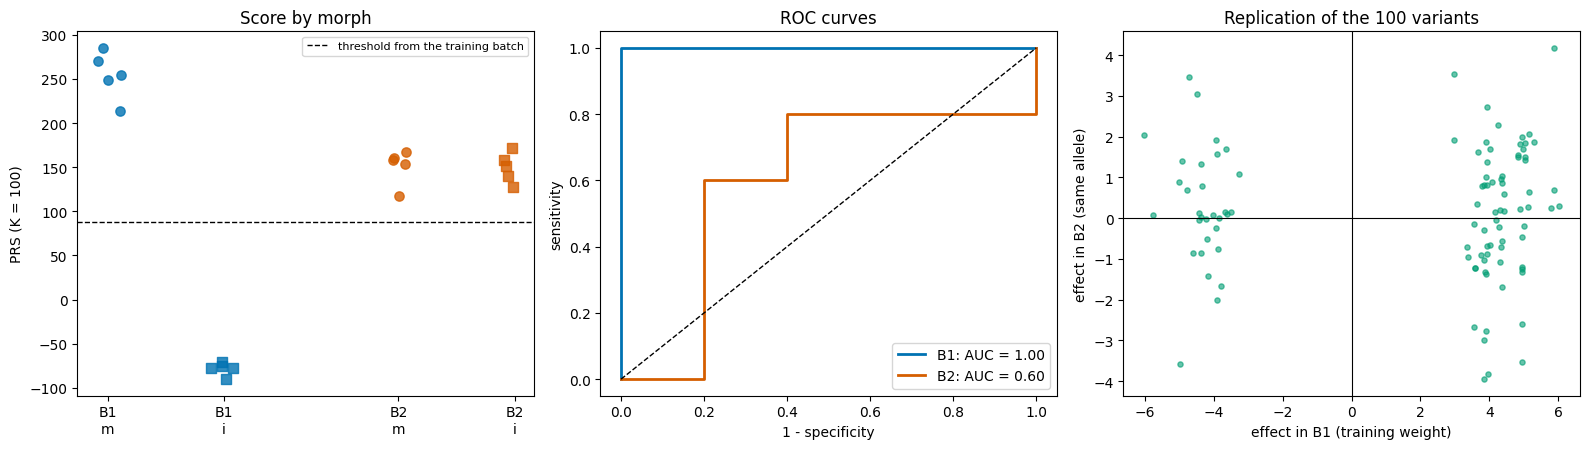

Test batch confusion matrix at the training threshold (88.11):


,predicted m,predicted i
true m,5,0
true i,5,0


accuracy 0.50, sensitivity 1.00, specificity 0.00, balanced accuracy 0.50   (in the training batch: accuracy 1.00)

Variants whose effect has the SAME sign in B2 as in B1: 0.49 (0.5 expected if the effects are pure noise); correlation of the effects: -0.03


In [14]:
selm = GW[:K_MAIN]; wm = CAND["beta"][selm].astype(np.float64)
s_tr = (wm[:, None] * dosage_rows(selm, TRAIN)).sum(0); s_te = (wm[:, None] * dosage_rows(selm, TEST)).sum(0)
thr, cl = classify(s_tr, Y[TRAIN], s_te, Y[TEST])

# ---- per-variant effects in the TEST batch, oriented to the training effect allele
S_TE = read_sumstats(TEST)
j = np.minimum(np.searchsorted(S_TE["key"], CAND["key"][selm]), len(S_TE["key"]) - 1); found = S_TE["key"][j] == CAND["key"][selm]
same_allele = found & (S_TE["ea"][j] == CAND["ea"][selm]); swapped = found & (S_TE["ea"][j] == CAND["nea"][selm])
b_te = np.where(same_allele, S_TE["beta"][j], np.where(swapped, -S_TE["beta"][j], np.nan)).astype(np.float64)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
rng_j = np.random.default_rng(1)
for xi, (b, s, y, col) in enumerate(((TRAIN, s_tr, Y[TRAIN], "#0072B2"), (TEST, s_te, Y[TEST], "#D55E00"))):
    for m_, off, mk in ((1, 0.0, "o"), (0, 1.0, "s")):
        v = s[y == m_]; ax[0].scatter(xi * 2.5 + off + rng_j.uniform(-0.12, 0.12, len(v)), v, color=col, marker=mk, s=45, alpha=0.8)
ax[0].axhline(thr, color="k", ls="--", lw=1, label="threshold from the training batch"); ax[0].legend(fontsize=8)
ax[0].set_xticks([0, 1, 2.5, 3.5]); ax[0].set_xticklabels([f"{TRAIN}\nm", f"{TRAIN}\ni", f"{TEST}\nm", f"{TEST}\ni"]); ax[0].set_ylabel(f"PRS (K = {K_MAIN})"); ax[0].set_title("Score by morph")
for b, s, y, col in ((TRAIN, s_tr, Y[TRAIN], "#0072B2"), (TEST, s_te, Y[TEST], "#D55E00")):
    f_, t_ = roc_curve(s, y); ax[1].plot(f_, t_, color=col, lw=2, label=f"{b}: AUC = {auc(s, y):.2f}")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set(xlabel="1 - specificity", ylabel="sensitivity", title="ROC curves"); ax[1].legend()
okb = np.isfinite(b_te)
ax[2].scatter(CAND["beta"][selm][okb], b_te[okb], s=14, alpha=0.6, color="#009E73"); ax[2].axhline(0, color="k", lw=0.8); ax[2].axvline(0, color="k", lw=0.8)
ax[2].set(xlabel=f"effect in {TRAIN} (training weight)", ylabel=f"effect in {TEST} (same allele)", title=f"Replication of the {K_MAIN} variants")
plt.tight_layout(); savefig("prs_main_score"); plt.show()

conf = pd.DataFrame({"predicted m": [cl["test"]["tp"], int((Y[TEST] == 0).sum()) - cl["test"]["tn"]], "predicted i": [int((Y[TEST] == 1).sum()) - cl["test"]["tp"], cl["test"]["tn"]]}, index=["true m", "true i"])
print(f"Test batch confusion matrix at the training threshold ({thr:.2f}):"); display(conf)
print(f"accuracy {cl['test']['accuracy']:.2f}, sensitivity {cl['test']['sensitivity']:.2f}, specificity {cl['test']['specificity']:.2f}, balanced accuracy {cl['test']['balanced']:.2f}"
      f"   (in the training batch: accuracy {cl['train']['accuracy']:.2f})")
same_sign = np.mean(np.sign(b_te[okb]) == np.sign(CAND['beta'][selm][okb]))
print(f"\nVariants whose effect has the SAME sign in {TEST} as in {TRAIN}: {same_sign:.2f} (0.5 expected if the effects are pure noise); "
      f"correlation of the effects: {np.corrcoef(CAND['beta'][selm][okb], b_te[okb])[0, 1]:.2f}")

### 6.4 A different null: shuffling the weights

The label permutation asks "could *any* score of this kind reach this AUC in 10 butterflies?". A second null keeps the **same K variants and the same genotypes** but **shuffles the weights among variants** (so the score has no relation to the training GWAS). If the observed test AUC is not larger than these shuffled-weight AUCs, the training weights carry **no information** about the test batch.

observed test AUC = 0.600;  shuffled-weight AUC: mean 0.573, 2.5%-97.5% range [0.200, 0.880]
P (fraction of shuffled-weight AUCs >= observed) = 0.505


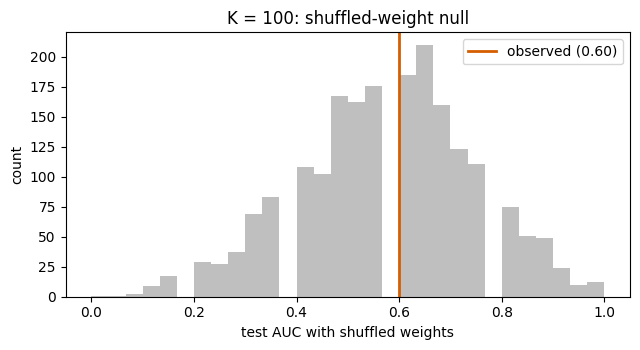

In [15]:
D_te = dosage_rows(selm, TEST); a_obs = auc(s_te, Y[TEST])
null_w = np.array([auc((rng.permutation(wm)[:, None] * D_te).sum(0), Y[TEST]) for _ in range(2000)])
print(f"observed test AUC = {a_obs:.3f};  shuffled-weight AUC: mean {null_w.mean():.3f}, 2.5%-97.5% range [{np.percentile(null_w, 2.5):.3f}, {np.percentile(null_w, 97.5):.3f}]")
print(f"P (fraction of shuffled-weight AUCs >= observed) = {(1 + (null_w >= a_obs - 1e-12).sum()) / (1 + len(null_w)):.3f}")
fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.hist(null_w, bins=30, color="0.75"); ax.axvline(a_obs, color="#D55E00", lw=2, label=f"observed ({a_obs:.2f})")
ax.set(xlabel="test AUC with shuffled weights", ylabel="count", title=f"K = {K_MAIN}: shuffled-weight null"); ax.legend(); plt.tight_layout(); savefig("prs_weight_shuffle"); plt.show()

### 6.5 Do the top variants of B1 replicate in B2?

The accuracy of a PRS is determined by how well the training **effects** predict the test **effects**. We bin the training-ranked clumps (the K best) and compute in the test batch the **fraction of variants whose effect has the same sign**. Under pure noise it is 0.5; a real polygenic signal gives a fraction clearly above 0.5, **at least for the best-ranked variants**. The band is the 95 % binomial interval around 0.5.

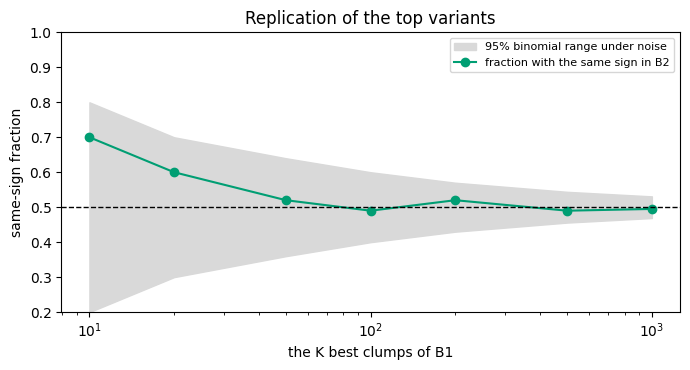

   K  same sign chance range
  10        0.7    0.20-0.80
  20        0.6    0.30-0.70
  50       0.52    0.36-0.64
 100       0.49    0.40-0.60
 200       0.52    0.43-0.57
 500       0.49    0.46-0.54
1000      0.495    0.47-0.53


In [16]:
j_all = np.minimum(np.searchsorted(S_TE["key"], CAND["key"][GW]), len(S_TE["key"]) - 1); f_all = S_TE["key"][j_all] == CAND["key"][GW]
b_all = np.where(f_all & (S_TE["ea"][j_all] == CAND["ea"][GW]), S_TE["beta"][j_all], np.where(f_all & (S_TE["ea"][j_all] == CAND["nea"][GW]), -S_TE["beta"][j_all], np.nan)).astype(np.float64)
sgn = np.sign(b_all) == np.sign(CAND["beta"][GW])
ks = [k for k in [10, 20, 50, 100, 200, 500, 1000, 2000, 5000] if k <= len(GW)]
fr = [np.nanmean(sgn[:k][np.isfinite(b_all[:k])]) for k in ks]; nn = [int(np.isfinite(b_all[:k]).sum()) for k in ks]
lo = [stats.binom.ppf(0.025, n, 0.5) / n for n in nn]; hi = [stats.binom.ppf(0.975, n, 0.5) / n for n in nn]
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.fill_between(ks, lo, hi, color="0.85", label="95% binomial range under noise")
ax.plot(ks, fr, "o-", color="#009E73", label=f"fraction with the same sign in {TEST}"); ax.axhline(0.5, color="k", ls="--", lw=1)
ax.set(xscale="log", ylim=(0.2, 1), xlabel=f"the K best clumps of {TRAIN}", ylabel="same-sign fraction", title="Replication of the top variants"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("prs_replication_sign"); plt.show()
print(pd.DataFrame({"K": ks, "same sign": np.round(fr, 3), "chance range": [f"{a:.2f}-{b:.2f}" for a, b in zip(lo, hi)]}).to_string(index=False))

**Interpretation.** If the same-sign fraction stays inside the grey band, the top variants of B1 are **not replicated** in B2: their effects were mostly noise or winner's-curse inflated, and a PRS built from them cannot predict. This is the practical meaning of "the GWAS was too small".

### 6.6 A score built only from the M-locus region

The genome-wide score treats the morph as polygenic. Biology says it is determined by **one major locus**. A score built from the **clumped variants inside the M-locus window** uses that prior knowledge. Because only variants **genuinely linked to the causal variant** carry signal, we expect this score to beat the genome-wide score, *if* B1 has power at the locus. We also score the genome-wide list **after removing the M-locus window** (`GWX`) to see how much of the signal, if any, comes from the rest of the genome.

M-locus score:


,score,K,AUC_train,AUC_test,test_CI_lo,test_CI_hi,perm_P,acc_test,bal_acc_test
0,M-locus window,1,0.820,0.460,0.100,0.800,0.600,0.500,0.500
1,M-locus window,2,0.880,0.160,0.000,0.480,0.967,0.400,0.400
2,M-locus window,3,0.920,0.000,0.000,0.000,1.000,0.200,0.200
3,M-locus window,5,0.960,0.080,0.000,0.320,0.993,0.200,0.200


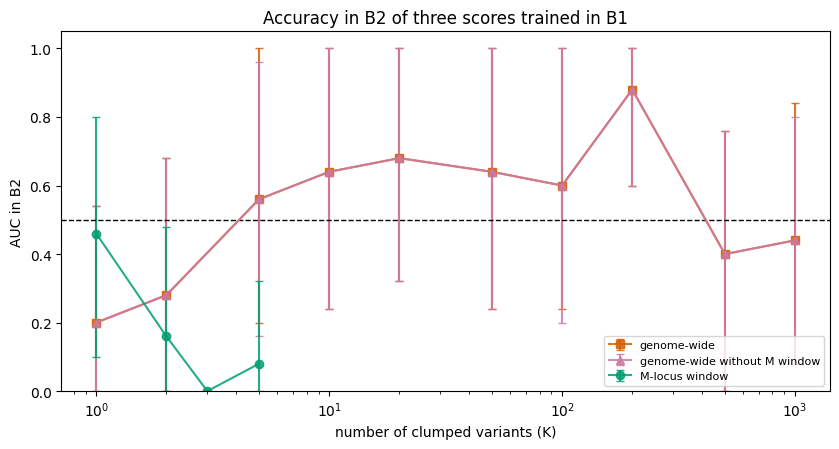

In [17]:
R_M = evaluate(MLIST, "M-locus window", [1, 2, 3, 5, 10, 20]) if len(MLIST) else pd.DataFrame()
R_GWX = evaluate(GWX, "genome-wide without M window", K_LIST)
ALL_PRS = pd.concat([R_GW, R_M, R_GWX], ignore_index=True)
cols = ["score", "K", "AUC_train", "AUC_test", "test_CI_lo", "test_CI_hi", "perm_P", "acc_test", "bal_acc_test"]
if len(R_M): print("M-locus score:"); display(R_M[cols].style.format(precision=3))
else: print("No variant of the M-locus window is among the candidates: the M-locus score is skipped.")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for R_, lab, col, mk in ((R_GW, "genome-wide", "#D55E00", "s"), (R_GWX, "genome-wide without M window", "#CC79A7", "^"), (R_M, "M-locus window", "#009E73", "o")):
    if len(R_): ax.errorbar(R_.K, R_.AUC_test, yerr=[R_.AUC_test - R_.test_CI_lo, R_.test_CI_hi - R_.AUC_test], fmt=mk + "-", color=col, capsize=3, label=lab, alpha=0.85)
ax.axhline(0.5, color="k", ls="--", lw=1); ax.set(xscale="log", ylim=(0, 1.05), xlabel="number of clumped variants (K)", ylabel=f"AUC in {TEST}", title=f"Accuracy in {TEST} of three scores trained in {TRAIN}")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); savefig("prs_three_scores"); plt.show()
ALL_PRS.to_csv(D["tables"] / "prs_accuracy_all_scores.tsv", sep="\t", index=False)

### 6.7 How much accuracy could we expect? The Daetwyler / Dudbridge approximation

Why is a PRS trained in 10 individuals hopeless for a polygenic trait, and how would it scale? With the approximation of Section 0.4 the expected $r^2$ between the **predicted** and the **true genetic value** is $Nh^2/(Nh^2+M_e)$ ($M_e$ = number of independent loci that matter, *the effective number of chromosome segments*). The table shows, for $h^2=0.5$, how many training individuals are needed for a given $M_e$. Note how a trait influenced by few loci (small $M_e$, like the morph) is predictable from small samples, whereas a highly polygenic one ($M_e$ in the thousands) needs thousands of individuals: the reason the **M-locus score** can work with 10 butterflies while the **genome-wide score** cannot.

Expected r^2 between predicted and true genetic value, h^2 = 0.5:


,M_e = 1,M_e = 10,M_e = 100,M_e = 1000,M_e = 10000
training individuals N,,,,,
10,0.83,0.33,0.05,0.00,0.00
100,0.98,0.83,0.33,0.05,0.00
1000,1.00,0.98,0.83,0.33,0.05
10000,1.00,1.00,0.98,0.83,0.33
100000,1.00,1.00,1.00,0.98,0.83


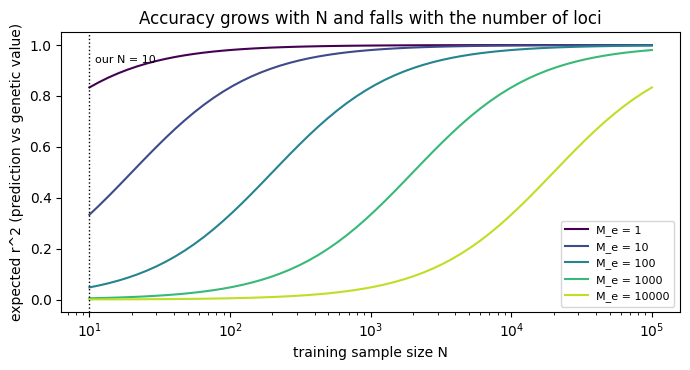

In [18]:
h2_ = 0.5
tab = pd.DataFrame({f"M_e = {me}": [n * h2_ / (n * h2_ + me) for n in (10, 100, 1000, 10000, 100000)] for me in (1, 10, 100, 1000, 10000)},
                   index=pd.Index([10, 100, 1000, 10000, 100000], name="training individuals N"))
print("Expected r^2 between predicted and true genetic value, h^2 = 0.5:")
display(tab.style.format("{:.2f}"))
fig, ax = plt.subplots(figsize=(7, 3.8))
Ns = np.logspace(1, 5, 60)
for me, col in zip((1, 10, 100, 1000, 10000), plt.cm.viridis(np.linspace(0, 0.9, 5))):
    ax.plot(Ns, Ns * h2_ / (Ns * h2_ + me), color=col, label=f"M_e = {me}")
ax.axvline(10, color="k", ls=":", lw=1); ax.text(11, 0.93, "our N = 10", fontsize=8)
ax.set(xscale="log", xlabel="training sample size N", ylabel="expected r^2 (prediction vs genetic value)", title="Accuracy grows with N and falls with the number of loci"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("prs_theory_accuracy"); plt.show()

---
# PART 2: How Heritable Is Wing Colour? GREML with GCTA

Part 1 asked "*can we predict the morph from a handful of variants?*" (answer: only through the M locus, and only if the data have power). Part 2 asks a different question: **what fraction of the variance of the trait is captured by ALL the common variants together**, without ever identifying which variants matter? This is the question answered by **GREML** (Genome-based REstricted Maximum Likelihood), implemented in **GCTA** (*Genome-wide Complex Trait Analysis*, Yang, Lee, Goddard & **Visscher** 2011), whose model and formulas were introduced in Sections 0.5-0.7.

Unlike Part 1 we use **all 20 butterflies together** (no batches): a variance-component analysis needs every individual it can get, and the two batches only existed to give us a training and a test set.

### The plan of Part 2

| Section | What we do |
|---|---|
| 7 | Call variants jointly in **all 20 butterflies** with ANGSD (a subset of chromosomes, to keep the run short) |
| 8 | Build the **genomic relationship matrix (GRM)** ourselves from dosages and write it in the **GCTA binary format** |
| 9 | Look at the GRM: is it a sensible relationship matrix? Cross-check our formula against `gcta64 --make-grm` |
| 10 | Run **GCTA REML**: observed-scale and **liability-scale** heritability, likelihood-ratio test, and a cross-check with a REML we write in Python |
| 11 | **Partition** the variance: the M chromosome versus the rest of the genome (`--mgrm`) |
| 12 | **Simulation**: how accurate is GREML with n = 20 when we know the true $h^2$? |
| 13 | How many individuals would we need? |

> **Be realistic.** Published GREML analyses use **thousands** of individuals. With n = 20 the standard error of $\hat h^2$ is huge. We run the analysis because it is the best way to understand the method, and the simulation of Section 12 will show you exactly what to expect.

## 7. Joint Variant Calling in All 20 Butterflies

### 7.1 Which chromosomes?

Calling variants in the whole genome of 20 butterflies would take far longer than this tutorial deserves, and the GRM does not need every variant. We therefore restrict the run to **`N_GRM_CHR` chromosomes**: the **M chromosome** (it carries the causal locus) plus the **smallest autosomes** (fastest to process). Set `GRM_CHR_LABELS` in the parameter cell to choose your own list, or increase `N_GRM_CHR` to use more of the genome (better GRM, longer run).

Because the M chromosome is on the list, we can later ask *how much of the heritability sits on the M chromosome and how much on the other five* (Section 11).

### 7.2 The ANGSD command

| Option | Meaning |
|---|---|
| `-b bam_list.txt` | the 20 BAM files **in the order of `batch_assignment.tsv`** (the order of the individuals in the output) |
| `-rf regions.txt` | restrict to the chosen sequences |
| `-GL 2` | GATK genotype-likelihood model (as in the earlier notebooks) |
| `-doMajorMinor 1` | infer major and minor alleles from the genotype likelihoods (no reference needed) |
| `-doMaf 1` | estimate the minor-allele frequency (EM algorithm) |
| `-doPost 1`, `-doGlf 2` | posterior genotype probabilities and BEAGLE text output of the likelihoods |
| `-SNP_pval 1e-6` | keep only sites that are polymorphic with $P<10^{-6}$ |
| `-minMaf`, `-minInd` | at least `GRM_MIN_MAF` frequency and at least half of the individuals with reads |
| read filters | same mapping/base-quality filters as before |

In [19]:
# ---- choose the chromosomes of the joint run
fai["chrom_label"] = fai.label
lab_ok = fai[fai.label.notna()].copy()
if GRM_CHR_LABELS:
    chosen = [str(l) for l in GRM_CHR_LABELS]
    if M_LABEL not in chosen: chosen = [M_LABEL] + chosen
else:
    others = lab_ok[lab_ok.label != M_LABEL].sort_values("length").label.tolist()[: max(0, N_GRM_CHR - 1)]
    chosen = [M_LABEL] + others
CHR_RUN = lab_ok[lab_ok.label.isin(chosen)].copy()
assert len(CHR_RUN) == len(chosen), f"some requested chromosome labels were not found: {sorted(set(chosen) - set(CHR_RUN.label))}"
print(CHR_RUN[["label", "contig", "length"]].to_string(index=False))
print(f"\nTotal length analysed: {CHR_RUN.length.sum() / 1e6:.1f} Mb of {fai.length.sum() / 1e6:.1f} Mb in the assembly")

# ---- the 20 BAM files, in the order of batch_assignment.tsv
JOINT_IDS = ba.sampleID.tolist(); N_IND = len(JOINT_IDS)
JOINT_MORPH = ba.morph.to_numpy(); Y_JOINT = (JOINT_MORPH == CASE_MORPH).astype(int)
ANG = D["angsd"]
bams = [BAM_DIR / f"{s}.sorted.bam" for s in JOINT_IDS]
missing = [str(b) for b in bams if not b.exists()]
assert not missing, "BAM files not found: " + ", ".join(missing[:3]) + " ..."
(ANG / "bam_list_joint.txt").write_text("\n".join(map(str, bams)) + "\n")
(ANG / "regions_joint.txt").write_text("\n".join(CHR_RUN.contig) + "\n")
print(f"{N_IND} butterflies ({int(Y_JOINT.sum())} {CASE_MORPH} morphs, {int((1 - Y_JOINT).sum())} others)")

label            contig   length
  102 JBBEEQ010000102.1     1000
  114 JBBEEQ010000114.1     1000
  135 JBBEEQ010000135.1     1000
  141 JBBEEQ010000141.1     1000
  148 JBBEEQ010000148.1     1000
   26 JBBEEQ010000026.1 11431643

Total length analysed: 11.4 Mb of 438.1 Mb in the assembly
20 butterflies (10 m morphs, 10 others)


In [20]:
JOINT = ANG / "joint20"
READ_FILTERS = f"-minMapQ {MIN_MAPQ} -minQ {MIN_BASEQ} -uniqueOnly 1 -remove_bads 1 -only_proper_pairs 0"
if not done(f"{JOINT}.beagle.gz", f"{JOINT}.mafs.gz"):
    run(f"angsd -b {ANG / 'bam_list_joint.txt'} -rf {ANG / 'regions_joint.txt'} -GL {GL_MODEL} -doMajorMinor 1 -doMaf 1 -doCounts 1 -doPost 1 -doGlf 2 "
        f"-SNP_pval {SNP_PVAL} -minMaf {GRM_MIN_MAF} -minInd {int(N_IND * (1 - GRM_MAX_UNINFORMATIVE))} {READ_FILTERS} -nThreads {THREADS} -out {JOINT}",
        log=ANG / "angsd_joint20.log", show=6)
else:
    print("ANGSD output already exists: skipping the run (set FORCE = True to redo it).")
if not (Path(f"{JOINT}.beagle.gz").exists() and Path(f"{JOINT}.mafs.gz").exists()):
    print((ANG / "angsd_joint20.log").read_text()[-3000:])
    raise AssertionError("ANGSD produced no output: see the log above (also saved as angsd_joint20.log on Drive)")
nsnp = sum(1 for _ in gzip.open(f"{JOINT}.mafs.gz", "rt")) - 1
print(f"\nvariants called in the {N_IND} butterflies: {nsnp:,}")

$ angsd -b /content/drive/MyDrive/GWAS/prs_gcta_HypMis/angsd/bam_list_joint.txt -rf /content/drive/MyDrive/GWAS/prs_gcta_HypMis/angsd/regions_joint.txt -GL 2 -doMajorMinor 1 -doMaf 1 -doCounts 1 -doPost 1 -doGlf 2 -SNP_pval 1e-06 -minMaf 0.05 -minInd 10 -minMapQ 30 -minQ 20 -uniqueOnly 1 -remove_bads 1 -only_proper_pairs 0 -nThreads 2 -out /content/drive/MyDrive/GWAS/prs_gcta_HypMis/angsd/joint20
	-> Fri Nov 13 10:56:57 2026
	-> Arguments and parameters for all analysis are located in .arg file
	-> Total number of sites analyzed: 10517919
	-> Number of sites retained after filtering: 373410 
	[ALL done] cpu-time used =  276.22 sec
	[ALL done] walltime used =  322.00 sec
[done in 322.8 s, exit code 0]

variants called in the 20 butterflies: 373,410


## 8. Building the Genomic Relationship Matrix (GRM)

### 8.1 From genotype likelihoods to standardised genotypes

The GRM formula of Section 0.6 needs a **genotype value** per individual and variant. With low-coverage data we use the **posterior dosage** (Section 5.1). The steps for each variant $i$ with minor allele frequency $p_i$ (estimated from the dosages of the 20 butterflies):

$$ z_{ij}=\frac{x_{ij}-2p_i}{\sqrt{2p_i(1-p_i)}} \qquad\text{and}\qquad A_{jk}=\frac1M\sum_{i=1}^{M} z_{ij}\,z_{ik}.$$

* the numerator **centres** the genotype (rare alleles contribute more when shared);
* the denominator **standardises** each variant to variance 1, so that every variant has the same prior weight. (This encodes the GCTA assumption that each SNP has effect variance $\sigma_g^2/M$ irrespective of its frequency. The `--gcta-alpha`/LDAK options would change it, see Section 14.)

An individual without reads at a variant has dosage $2p_i$, hence $z=0$: it contributes nothing to relationships at that variant.

### 8.2 Inclusion rules

A variant enters the GRM if its frequency satisfies $p_i\ge$ `GRM_MIN_MAF` (and $\le 1-$ `GRM_MIN_MAF`), and at most `GRM_MAX_UNINFORMATIVE` of the individuals lack reads at it. We keep the matrix of standardised genotypes $Z$ ($M\times 20$) in memory (it is small) because the simulations of Section 12 need it.

In [21]:
def build_Z(prefix, n):
    # Standardised genotype matrix Z (variants x individuals) from the joint ANGSD run, with chromosome, position and alleles of each variant.
    Zs, CI, POS, FQ, MAJ, MIN, NIN = [], [], [], [], [], [], []
    rb = pd.read_csv(f"{prefix}.beagle.gz", sep="\t", chunksize=CHUNK)
    rm = pd.read_csv(f"{prefix}.mafs.gz", sep="\t", chunksize=CHUNK, usecols=["chromo", "position", "major", "minor", "knownEM", "nInd"],
                     dtype={"chromo": str, "major": str, "minor": str})
    for cb, cm in zip(rb, rm):
        assert len(cb) == len(cm), "BEAGLE and MAFS files have different numbers of rows"
        assert (cb.shape[1] - 3) // 3 == n, f"BEAGLE has {(cb.shape[1] - 3) // 3} individuals, expected {n}"
        G = cb.iloc[:, 3:].to_numpy(np.float64).reshape(len(cb), n, 3)
        flat = (G.max(-1) - G.min(-1)) < 1e-3
        G = G / np.maximum(G.sum(-1, keepdims=True), 1e-300)
        p0 = np.clip(np.nan_to_num(pd.to_numeric(cm.knownEM, errors="coerce").to_numpy(np.float64), nan=0.5), 1e-6, 1 - 1e-6)
        post = G * np.stack([(1 - p0) ** 2, 2 * p0 * (1 - p0), p0 ** 2], 1)[:, None, :]
        post /= post.sum(-1, keepdims=True)
        dose = post[..., 1] + 2 * post[..., 2]
        dose = np.where(flat, (2 * p0)[:, None], dose)                               # no reads: population-average dosage
        p = dose.mean(1) / 2
        ok = (np.minimum(p, 1 - p) >= GRM_MIN_MAF) & (flat.mean(1) <= GRM_MAX_UNINFORMATIVE)
        z = (dose - 2 * p[:, None]) / np.sqrt(np.maximum(2 * p * (1 - p), 1e-12))[:, None]
        ci = cm.chromo.map(CONTIG_INDEX).fillna(-1).to_numpy(np.int32)
        ok &= ci >= 0
        Zs.append(z[ok].astype(np.float32)); CI.append(ci[ok]); POS.append(cm.position.to_numpy(np.int64)[ok]); FQ.append(p[ok])
        MAJ.append(cm.major.map(ALLELE_CODE).fillna(4).to_numpy(np.int8)[ok]); MIN.append(cm.minor.map(ALLELE_CODE).fillna(4).to_numpy(np.int8)[ok]); NIN.append(flat.mean(1)[ok])
    cat = lambda L, dt: np.concatenate(L) if L else np.zeros(0, dt)
    return dict(Z=np.vstack(Zs) if Zs else np.zeros((0, n), np.float32), ci=cat(CI, np.int32), pos=cat(POS, np.int64), p=cat(FQ, np.float64),
                major=cat(MAJ, np.int8), minor=cat(MIN, np.int8), flat=cat(NIN, np.float64))

GZ = build_Z(JOINT, N_IND)
M_SNP = GZ["Z"].shape[0]
assert M_SNP > 100, f"only {M_SNP} variants passed the GRM filters: use more chromosomes (N_GRM_CHR) or relax the filters"
print(f"variants in the GRM: {M_SNP:,}   (MAF >= {GRM_MIN_MAF}, at most {GRM_MAX_UNINFORMATIVE:.0%} individuals without reads)")
on_M = GZ["ci"] == M_CI
chr_tab = pd.DataFrame({"chromosome": LABEL_OF_CI[GZ["ci"]]}).value_counts().rename("variants").reset_index()
display(chr_tab)
print(f"variants on the M chromosome: {int(on_M.sum()):,}   on the other chromosomes: {int((~on_M).sum()):,}")

variants in the GRM: 373,410   (MAF >= 0.05, at most 50% individuals without reads)


,chromosome,variants
0,26,373381
1,114,27
2,102,2


variants on the M chromosome: 373,381   on the other chromosomes: 29


### 8.3 The GCTA binary GRM format

GCTA reads a GRM from **three files** with a common prefix:

| File | Content |
|---|---|
| `prefix.grm.id` | text, one line per individual: family ID and individual ID |
| `prefix.grm.bin` | binary: the **lower triangle including the diagonal**, row by row ($A_{11}, A_{21}, A_{22}, A_{31},\dots$), each element a 32-bit float |
| `prefix.grm.N.bin` | binary, same layout: the **number of variants** used for each element |

This is exactly the format GCTA writes with `--make-grm`, so any GRM we build (from dosages, from a different software, or from a single chromosome) can be analysed by GCTA. We write the **whole-data GRM**, the **M-chromosome GRM** and the **rest-of-genome GRM**, plus functions to read them back.

In [ ]:
def write_grm(A, nsnp, prefix, ids):
    # Write the matrix A (n x n) in the GCTA binary format; nsnp = number of variants behind it.
    n = len(ids); iu = np.tril_indices(n)                                         # row-major lower triangle incl. diagonal
    A[iu].astype("<f4").tofile(f"{prefix}.grm.bin")
    np.full(len(iu[0]), nsnp, dtype="<f4").tofile(f"{prefix}.grm.N.bin")
    Path(f"{prefix}.grm.id").write_text("".join(f"{i}\t{i}\n" for i in ids))

def read_grm(prefix):
    ids = [l.split()[1] for l in Path(f"{prefix}.grm.id").read_text().splitlines()]; n = len(ids)
    v = np.fromfile(f"{prefix}.grm.bin", dtype="<f4").astype(np.float64); A = np.zeros((n, n)); iu = np.tril_indices(n)
    assert len(v) == len(iu[0]), "grm.bin has an unexpected size"
    A[iu] = v; A = A + A.T - np.diag(np.diag(A))
    return A, ids

def grm_of(mask):
    Zs = GZ["Z"][mask].astype(np.float64)
    return Zs.T @ Zs / max(1, Zs.shape[0]), int(mask.sum())

GR = D["gcta"]
A_all, n_all = grm_of(np.ones(M_SNP, bool)); A_M, n_M = grm_of(on_M); A_R, n_R = grm_of(~on_M)
for nm, A_, n_ in (("all", A_all, n_all), ("Mchr", A_M, n_M), ("rest", A_R, n_R)):
    write_grm(A_, n_, GR / f"grm_{nm}", JOINT_IDS)
B, _ = read_grm(GR / "grm_all"); print("round trip through the binary file: max |difference| =", float(np.abs(B - A_all).max()), "(float32 precision ~1e-7)")
print({k: (GR / f"grm_{k}.grm.bin").stat().st_size for k in ("all", "Mchr", "rest")}, "bytes; expected", 4 * N_IND * (N_IND + 1) // 2)

round trip through the binary file: max |difference| = 2.913147234551161e-08 (float32 precision ~1e-7)
{'all': 840, 'Mchr': 840, 'rest': 840} bytes; expected 840


## 9. Inspecting the GRM

A GRM is a sanity check of the whole genotype dataset. We look at:

* the **diagonal** $A_{jj}=1+F_j$ (with $F$ the inbreeding coefficient): its mean should be close to **1** for good genotype data; with **low-coverage dosages** it is usually somewhat **below 1**, because posterior dosages are shrunk towards the population mean $2p$ where reads are scarce (a uniform shrinkage of $A$ rescales $\sigma_g^2$ but does not change the ratio $h^2$ much); values very different between individuals point to depth-related artefacts or inbreeding;
* the **off-diagonal** elements (relatedness between pairs): near 0 for unrelated individuals, about 0.5 for full sibs or parent-offspring, **negative values are normal** (individuals less related than the average pair);
* the **block structure** when the individuals are ordered by morph, and the first **principal components** (eigenvectors) of the GRM.

Remember that GREML uses the *similarity between pairs of butterflies* and asks whether pairs that are **genetically more similar are also more similar in phenotype**. The signal for $h^2$ is the covariance between the off-diagonal elements of $A$ and the products $y_jy_k$.

diagonal: mean 0.482, range 0.237-0.636;  off-diagonal: mean -0.025, sd 0.007, range -0.043--0.009
mean relatedness of pairs with the same morph: -0.0255;  of pairs with different morphs: -0.0253


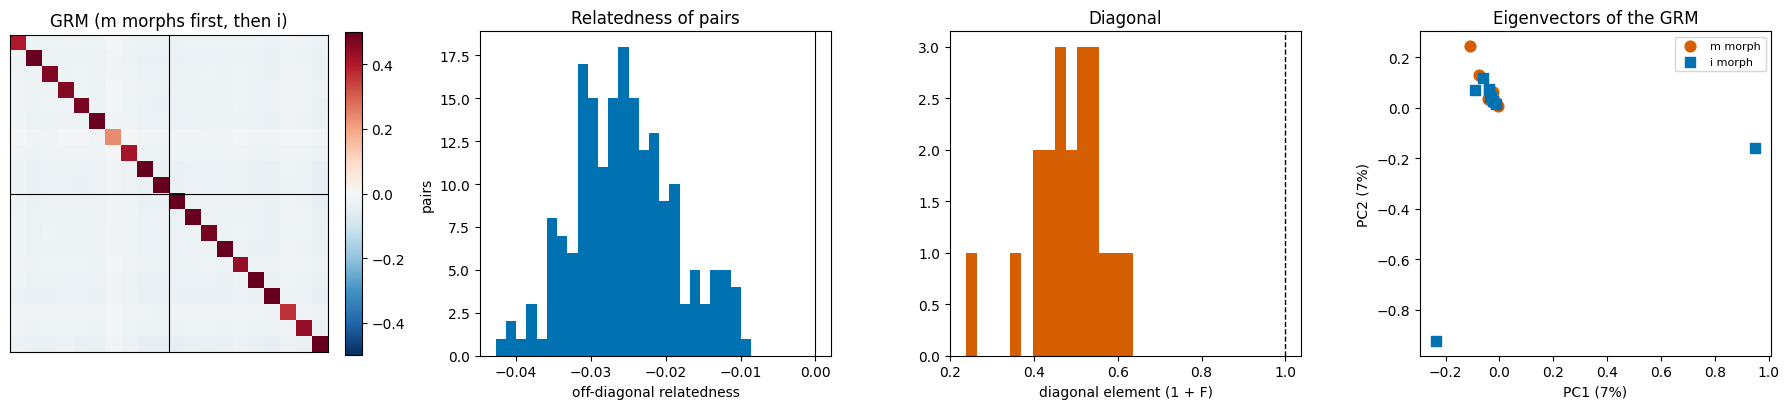

In [ ]:
order = np.argsort(-Y_JOINT, kind="stable")                       # m morphs first
d = np.diag(A_all); off = A_all[np.triu_indices(N_IND, 1)]
print(f"diagonal: mean {d.mean():.3f}, range {d.min():.3f}-{d.max():.3f};  off-diagonal: mean {off.mean():.3f}, sd {off.std():.3f}, range {off.min():.3f}-{off.max():.3f}")
same = (Y_JOINT[:, None] == Y_JOINT[None, :]); iu = np.triu_indices(N_IND, 1)
print(f"mean relatedness of pairs with the same morph: {A_all[iu][same[iu]].mean():.4f};  of pairs with different morphs: {A_all[iu][~same[iu]].mean():.4f}")

ev, evec = np.linalg.eigh(A_all); ev, evec = ev[::-1], evec[:, ::-1]
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
im = ax[0].imshow(A_all[np.ix_(order, order)], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
ax[0].set_title("GRM (m morphs first, then i)"); ax[0].set_xticks([]); ax[0].set_yticks([]); plt.colorbar(im, ax=ax[0], fraction=0.046)
ax[0].axhline(int(Y_JOINT.sum()) - 0.5, color="k", lw=0.8); ax[0].axvline(int(Y_JOINT.sum()) - 0.5, color="k", lw=0.8)
ax[1].hist(off, bins=25, color="#0072B2"); ax[1].axvline(0, color="k", lw=0.8); ax[1].set(xlabel="off-diagonal relatedness", ylabel="pairs", title="Relatedness of pairs")
ax[2].hist(d, bins=15, color="#D55E00"); ax[2].axvline(1, color="k", ls="--", lw=1); ax[2].set(xlabel="diagonal element (1 + F)", title="Diagonal")
for lab, col, mk in ((1, "#D55E00", "o"), (0, "#0072B2", "s")):
    ax[3].scatter(evec[Y_JOINT == lab, 0], evec[Y_JOINT == lab, 1], color=col, marker=mk, s=60, label=("m morph" if lab else "i morph"))
ax[3].set(xlabel=f"PC1 ({ev[0] / ev.sum():.0%})", ylabel=f"PC2 ({ev[1] / ev.sum():.0%})", title="Eigenvectors of the GRM"); ax[3].legend(fontsize=8)
plt.tight_layout(); savefig("grm_overview"); plt.show()

**What to look for.** If the two morphs separated clearly in the first PC, the morph would be confounded with **population structure** (the butterflies of the two morphs would simply come from different populations). GREML treats *all* genome-wide similarity as potential heritability; strong stratification inflates the estimate. Here the butterflies come from a single population, so we expect no clean separation, and the GRM should mainly reflect distant relatedness among the 20 butterflies.

### 9.1 Cross-check: our GRM versus `gcta64 --make-grm`

We want to be sure that our own matrix agrees with what GCTA itself computes. We export the **best-guess genotypes** (dosage rounded to 0, 1, 2) of a random subset of variants (at most 100,000) as PLINK files, let GCTA build a GRM from them with `--make-grm`, and compare. Two comparisons are informative:

* our formula applied to the **same rounded genotypes**: this should agree with GCTA to numerical precision (a test of the formula and of our binary writer);
* our **dosage-based** GRM (all variants): this should be highly correlated but not identical, because dosages keep the genotype uncertainty that rounding throws away.

(GCTA's `--autosome-num 40` is needed because GCTA assumes 22 human autosomes and would otherwise ignore chromosomes numbered above 22.)

In [ ]:
rng_x = np.random.default_rng(SEED)
sub = np.sort(rng_x.choice(M_SNP, size=min(M_SNP, 100_000), replace=False))
bg = np.clip(np.rint(GZ["Z"][sub].astype(np.float64) * np.sqrt(2 * GZ["p"][sub] * (1 - GZ["p"][sub]))[:, None] + 2 * GZ["p"][sub][:, None]), 0, 2).astype(int)   # best-guess genotype 0/1/2
pb = bg.mean(1) / 2; keep_b = (np.minimum(pb, 1 - pb) >= 0.01); bg, sub = bg[keep_b], sub[keep_b]
mj, mn = ALLELE_LETTER[GZ["major"][sub]], ALLELE_LETTER[GZ["minor"][sub]]
lab_num = np.array([int(re.sub(r"\D", "", str(LABEL_OF_CI[c])) or 0) for c in GZ["ci"][sub]])
PL = GR / "bestguess"
with open(f"{PL}.map", "w") as f:
    for k in range(len(sub)): f.write(f"{lab_num[k]}\tsnp{k}\t0\t{GZ['pos'][sub][k]}\n")
with open(f"{PL}.ped", "w") as f:
    for j, s in enumerate(JOINT_IDS):
        g = bg[:, j]; a1 = np.where(g == 2, mn, mj); a2 = np.where(g == 0, mj, mn)
        f.write(f"{s} {s} 0 0 0 -9 " + " ".join(f"{x} {y}" for x, y in zip(a1, a2)) + "\n")
run(f"plink --file {PL} --chr-set 40 --allow-no-sex --make-bed --out {PL}", log=GR / "plink_bestguess.log", show=3)
if GCTA:
    run(f"{GCTA} --bfile {PL} --autosome-num 40 --autosome --maf 0.01 --make-grm --thread-num {THREADS} --out {GR / 'grm_gcta_bestguess'}", log=GR / "gcta_make_grm.log", show=5)
    A_g, _ = read_grm(GR / "grm_gcta_bestguess")
    pbb = bg.mean(1) / 2; zb = (bg - 2 * pbb[:, None]) / np.sqrt(2 * pbb * (1 - pbb))[:, None]
    A_mine_bg = zb.T @ zb / zb.shape[0]
    iu_ = np.triu_indices(N_IND, 1)
    print(f"GCTA --make-grm versus our formula on the same best-guess genotypes: max |difference| = {np.abs(A_g - A_mine_bg).max():.2e}")
    print(f"GCTA best-guess GRM versus our dosage GRM (all variants): correlation of the off-diagonal elements = {np.corrcoef(A_g[iu_], A_all[iu_])[0, 1]:.3f}, "
          f"of the diagonals = {np.corrcoef(np.diag(A_g), np.diag(A_all))[0, 1]:.3f}")
    fig, ax = plt.subplots(figsize=(4.8, 4.4)); ax.scatter(A_g[iu_], A_all[iu_], s=14, alpha=0.7); lim = [min(A_g[iu_].min(), A_all[iu_].min()), max(A_g[iu_].max(), A_all[iu_].max())]
    ax.plot(lim, lim, "k--", lw=1); ax.set(xlabel="GCTA GRM from best-guess genotypes", ylabel="our dosage GRM", title="Relatedness of the 190 pairs"); plt.tight_layout(); savefig("grm_crosscheck"); plt.show()
else:
    print("GCTA not found: cross-check skipped.")

## 10. REML Heritability of the Morph

### 10.1 The phenotype file

GCTA reads a text file with three columns: family ID, individual ID and the phenotype. We code the **m morph = 1** and the other morph = 0. For a binary trait GCTA analyses the 0/1 variable as if it were quantitative and gives the heritability on the **observed scale**; with `--prevalence` it also converts it to the **liability scale**, the scale on which heritability of diseases (and of a discrete morph) is conventionally reported (Section 0.7):

$$h^2_L = h^2_O\;\frac{K(1-K)}{z^2}\;\frac{K(1-K)}{P(1-P)},$$

where $K$ is the **population prevalence** of the m morph (`PREVALENCE`), $P$ its proportion **in the sample** (here 10/20 = 0.5) and $z$ the height of the standard normal density at the liability threshold $\Phi^{-1}(1-K)$. The correction is needed because the sample is not drawn at random from the population: we picked 10 + 10 butterflies. **`PREVALENCE` is a biological assumption**: the frequency of the m morph among females in the natural population. Change it in the parameter cell and look at how the liability-scale estimate moves.

### 10.2 The GCTA command

```
gcta64 --reml --grm grm_all --pheno morph.txt --prevalence 0.5 --reml-lrt 1 --thread-num 4 --out reml_all
```

| Option | Meaning |
|---|---|
| `--reml` | run the REML analysis |
| `--grm prefix` | the GRM files of Section 8.3 |
| `--pheno file` | phenotype file (FID, IID, y) |
| `--prevalence K` | population prevalence: adds the liability-scale estimate to the output |
| `--reml-lrt 1` | likelihood-ratio test of the first variance component, $H_0:\sigma_g^2=0$ |
| `--reml-no-constrain` | allow **negative** variance estimates (otherwise estimates are constrained to $\ge0$ and may stick at 0): important for small samples because it avoids a biased distribution of estimates |

The result is the file `.hsq` with the variance components $V(G)$ and $V(e)$, the total $V_P$, the ratio $V(G)/V_P=\hat h^2$ with its **standard error**, the log-likelihoods, the LRT statistic and its P-value.

### 10.3 A REML we write ourselves

GCTA is a black box until you have implemented the same likelihood once. For the model $y\sim N(\mathbf 1\mu,\ \sigma_g^2A+\sigma_e^2I)$ the REML log-likelihood is

$$\ell_R(\sigma_g^2,\sigma_e^2)=-\tfrac12\Big[\log|V|+\log|X^{\top}V^{-1}X|+y^{\top}Py\Big],\qquad P=V^{-1}-V^{-1}X(X^{\top}V^{-1}X)^{-1}X^{\top}V^{-1}.$$

The `reml_python` function maximises this with SciPy (at n = 20 it takes milliseconds). The LRT uses the **50:50 mixture** of $\chi^2_0$ and $\chi^2_1$ (the null value 0 lies on the boundary of the parameter space), which is what GCTA does, so $P=\tfrac12\Pr(\chi^2_1>\mathrm{LRT})$.

In [ ]:
from scipy.optimize import minimize
Y_FILE = GR / "morph.txt"
pd.DataFrame({"FID": JOINT_IDS, "IID": JOINT_IDS, "y": Y_JOINT}).to_csv(Y_FILE, sep="\t", header=False, index=False)
P_SAMPLE = Y_JOINT.mean()

def obs_to_liab(h2o, K, P):
    # observed-scale -> liability-scale heritability (Lee et al. 2011, Eq. 17)
    z = stats.norm.pdf(stats.norm.ppf(1 - K)); return h2o * K * (1 - K) / z ** 2 * K * (1 - K) / (P * (1 - P))

def reml_python(y, As, constrain=True):
    # REML for y ~ N(mu, sum_k s_k A_k + s_e I) with an intercept; returns variances, h2 (=sum s_k / total), logL, and LRT of the first component.
    y = np.asarray(y, float); n = len(y); X = np.ones((n, 1)); As = As if isinstance(As, list) else [As]; sc = max(y.var(), 1e-12)
    def nll(th, drop_first=False):
        s = np.array(th, float) * sc; V = s[-1] * np.eye(n)
        for k, A in enumerate(As):
            if not (drop_first and k == 0): V = V + s[k] * A
        try: L = np.linalg.cholesky(V)
        except np.linalg.LinAlgError: return 1e10
        Vi = np.linalg.inv(V); XtVi = X.T @ Vi; M = XtVi @ X; P = Vi - Vi @ X @ np.linalg.solve(M, XtVi)
        return 0.5 * (2 * np.log(np.diag(L)).sum() + np.log(np.linalg.det(M)) + y @ P @ y)
    k = len(As) + 1; x0 = np.full(k, 1.0 / k); bnd = [(0, None)] * k if constrain else [(None, None)] * k
    best = min((minimize(nll, x0 * f, method="L-BFGS-B", bounds=bnd) for f in (1.0, 0.1, 3.0)), key=lambda r: r.fun)
    s = best.x * sc; tot = s.sum(); ll = -best.fun
    r0 = minimize(lambda t: nll([0.0] * (k - 1) + [t[0]], True), [1.0], method="L-BFGS-B", bounds=[(1e-9, None)])
    lrt = max(0.0, 2 * (ll + r0.fun)); pval = 0.5 * stats.chi2.sf(lrt, 1) if lrt > 0 else 0.5
    return dict(components=s[:-1], Ve=s[-1], Vp=tot, h2=s[:-1].sum() / tot, h2_each=s[:-1] / tot, logL=ll, LRT=lrt, P=pval)

def read_hsq(path):
    # Parse a GCTA .hsq file into a dictionary name -> (value, se)
    out = {}
    for line in Path(path).read_text().splitlines():
        parts = [p for p in line.rstrip("\n").split("\t") if p != ""]
        if len(parts) < 2 or parts[0] == "Source": continue
        try: out[parts[0]] = (float(parts[1]), float(parts[2]) if len(parts) > 2 else np.nan)
        except ValueError: pass
    return out

def gcta_reml(grm_prefixes, out, y_file=Y_FILE, mpheno=None, prevalence=None, noconstrain=False, lrt="1", threads=None, quiet=True):
    # Run gcta64 --reml for one GRM (str/Path) or several (list -> --mgrm). Returns the parsed .hsq (or None if GCTA failed).
    if isinstance(grm_prefixes, (str, Path)): grm_arg = f"--grm {grm_prefixes}"
    else:
        Path(f"{out}.mgrm.txt").write_text("\n".join(map(str, grm_prefixes)) + "\n"); grm_arg = f"--mgrm {out}.mgrm.txt"
    cmd = (f"{GCTA} --reml {grm_arg} --pheno {y_file} " + (f"--mpheno {mpheno} " if mpheno else "") + (f"--prevalence {prevalence} " if prevalence else "")
           + (f"--reml-lrt {lrt} " if lrt else "") + ("--reml-no-constrain " if noconstrain else "") + f"--thread-num {threads or THREADS} --out {out}")
    r = run(cmd, log=f"{out}.runlog", check=False, quiet=quiet, show=0)
    if r.returncode != 0 or not Path(f"{out}.hsq").exists():
        if not quiet: print((r.stdout or "")[-1500:] + (r.stderr or "")[-1500:])
        return None
    return read_hsq(f"{out}.hsq")

print("helper functions defined; phenotype file:", Y_FILE.name, f"(proportion of m morphs in the sample P = {P_SAMPLE:.2f})")

In [ ]:
# ---- (a) our own REML, (b) GCTA REML, constrained and unconstrained
mine_c = reml_python(Y_JOINT, A_all, constrain=True); mine_u = reml_python(Y_JOINT, A_all, constrain=False)
print(f"Python REML:  h2(observed) = {mine_c['h2']:.3f} (constrained)   {mine_u['h2']:.3f} (unconstrained);  LRT = {mine_c['LRT']:.2f}, P = {mine_c['P']:.3g};  logL = {mine_c['logL']:.3f}")
print(f"              liability scale (K = {PREVALENCE}): {obs_to_liab(mine_c['h2'], PREVALENCE, P_SAMPLE):.3f}")
HSQ = {}
if GCTA:
    for nm, nc in (("constrained", False), ("unconstrained", True)):
        h = gcta_reml(GR / "grm_all", GR / f"reml_all_{nm}", prevalence=PREVALENCE, noconstrain=nc)
        if h is None: print(f"GCTA ({nm}) did not converge or failed: see {GR / f'reml_all_{nm}.runlog'}"); continue
        HSQ[nm] = h
        print(f"\nGCTA ({nm}):"); print(pd.DataFrame(h, index=["value", "SE"]).T.to_string(float_format=lambda v: f"{v:.4g}"))
else:
    print("GCTA not found: only the Python REML is shown.")

### 10.4 Reading the result

The rows to look at in the GCTA output:

* **`V(G)/Vp`**: the estimated heritability on the **observed scale** and its SE.
* **`V(G)/Vp_L`** (printed because we supplied `--prevalence`): the **liability-scale** heritability. This is the number to quote for a binary trait.
* **`Pval`** of the LRT: the evidence that $\sigma_g^2>0$.
* **`logL` / `logL0`** and **`LRT`**: log-likelihoods of the model with and without the genetic component.

Four warnings for a sample as small as this one:

1. The **standard error** will be of the order of the estimate itself (Section 13 gives the formula): the confidence interval covers almost the whole $[0,1]$ range.
2. The **constrained** estimate is **truncated at 0 and at 1**: a boundary value (0 or 1) says that the data are not informative, not that the heritability is exactly that.
3. The **liability-scale** value is the observed-scale value multiplied by a factor that is **larger than 1** when $K$ is far from the sample proportion's logistic range, so it can exceed 1 when the observed-scale estimate is at its boundary: this is a symptom of an uninformative sample, not a result.
4. **GREML estimates the *additive* variance explained by the variants in the GRM.** A trait with a single dominant locus can have a narrow-sense $h^2$ below 1 even if the genotype determines the morph completely (dominance variance is not additive variance), and variants that are not in (or not tagged by) the GRM are invisible to it.

The figure compares the three versions of the estimate.

In [ ]:
rows = [("Python REML (constrained)", mine_c["h2"], np.nan), ("Python REML (unconstrained)", mine_u["h2"], np.nan)]
for nm, h in HSQ.items(): rows.append((f"GCTA {nm}", h["V(G)/Vp"][0], h["V(G)/Vp"][1]))
est = pd.DataFrame(rows, columns=["method", "h2_observed", "se"])
est["h2_liability"] = [obs_to_liab(v, PREVALENCE, P_SAMPLE) for v in est.h2_observed]
est["se_liability"] = [obs_to_liab(s, PREVALENCE, P_SAMPLE) if np.isfinite(s) else np.nan for s in est.se]
display(est.style.format({c: "{:.3f}" for c in est.columns if c != "method"}))
fig, ax = plt.subplots(figsize=(8, 3.6)); yy = np.arange(len(est))[::-1]
ax.errorbar(est.h2_observed, yy, xerr=[1.96 * est.se.fillna(0)] * 2, fmt="o", color="#0072B2", capsize=4)
ax.axvline(0, color="k", lw=0.8); ax.axvline(1, color="k", lw=0.8); ax.set_yticks(yy); ax.set_yticklabels(est.method)
ax.set(xlabel="heritability on the observed scale (bars: 95% CI = estimate +- 1.96 SE, where GCTA gives the SE)", title="GREML estimates of the heritability of the m/i morph"); plt.tight_layout(); savefig("reml_estimates"); plt.show()

## 11. Partitioning the Heritability: M Chromosome versus the Rest

GREML can estimate **several variance components at once**. With two GRMs, $A_M$ (variants on the M chromosome) and $A_R$ (variants on the other chromosomes of the run), the model is

$$ y = X\beta + g_M + g_R + \varepsilon,\qquad g_M\sim N(0,A_M\sigma^2_M),\ g_R\sim N(0,A_R\sigma^2_R).$$

GCTA does this with `--mgrm`, which takes a text file listing the GRM prefixes. The estimates $\sigma_M^2/V_P$ and $\sigma_R^2/V_P$ tell **where along the genome the heritability sits**, which is exactly what Yang et al. (2011) did for human height (variance explained per chromosome is proportional to chromosome length, a signature of a polygenic trait) and what Section 0.9 predicts will look different for a **single-locus** trait: the whole heritability on one chromosome, nothing on the others.

> **Caveats.** (i) The M chromosome GRM is built from several thousand correlated variants,
> which all tag the **same** causal locus; (ii) with n = 20 the two components are strongly negatively correlated in the estimation (their sum is much better determined than either of them), so look at the *sum* and at the SEs; (iii) we only have `N_GRM_CHR` chromosomes, so "rest" means the other chromosomes **of this run**.

In [ ]:
mine_p = reml_python(Y_JOINT, [A_M, A_R], constrain=False)
print(f"Python REML, two components (unconstrained):  h2(M chromosome) = {mine_p['h2_each'][0]:.3f}   h2(rest) = {mine_p['h2_each'][1]:.3f}   sum = {mine_p['h2']:.3f}")
mine_pc = reml_python(Y_JOINT, [A_M, A_R], constrain=True)
print(f"Python REML, two components (constrained):    h2(M chromosome) = {mine_pc['h2_each'][0]:.3f}   h2(rest) = {mine_pc['h2_each'][1]:.3f}   LRT for the M component = {mine_pc['LRT']:.2f}, P = {mine_pc['P']:.3g}")
HSQ_P = None
if GCTA:
    for nm, nc in (("constrained", False), ("unconstrained", True)):
        h = gcta_reml([GR / "grm_Mchr", GR / "grm_rest"], GR / f"reml_partition_{nm}", prevalence=None, noconstrain=nc, lrt="1")
        if h is None: print(f"GCTA --mgrm ({nm}) failed or did not converge: see {GR / f'reml_partition_{nm}.runlog'}"); continue
        print(f"\nGCTA --mgrm ({nm}):"); print(pd.DataFrame(h, index=["value", "SE"]).T.to_string(float_format=lambda v: f"{v:.4g}")); HSQ_P = h
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(["M chromosome", "other chromosomes"], mine_p["h2_each"], color=["#D55E00", "#0072B2"]); ax.axhline(0, color="k", lw=0.8)
ax.set(ylabel="variance explained / V_P (Python REML, unconstrained)", title="Where is the heritability?"); plt.tight_layout(); savefig("reml_partition"); plt.show()

## 12. How Accurate Is GREML with n = 20? A Simulation with a Known Truth

The only honest way to judge an estimator is to run it on data where **the answer is known**. We keep the real genotype matrix $Z$ of the 20 butterflies and **simulate phenotypes** for a chosen true heritability $h^2$:

$$ g=Z\,u,\quad u_i\sim N\!\left(0,\frac{h^2}{M}\right),\qquad e\sim N(0,1-h^2),\qquad y=g+e.$$

Every one of the $M$ variants has a small random effect (a perfectly **polygenic** trait, as the GREML model assumes), and **all causal variants are genotyped**, i.e. this is the *best case* for GREML. We simulate `N_SIM` phenotypes for each true value in `SIM_H2` (0 = no genetic effect at all, to check the false-positive rate), analyse each with GCTA (`--reml --reml-no-constrain`, many runs in parallel) and with our Python REML, and plot the distribution of the estimates.

The simulated phenotypes are **quantitative**, so no prevalence correction applies.

In [ ]:
from concurrent.futures import ThreadPoolExecutor
rng_s = np.random.default_rng(SEED + 1)
Zd = GZ["Z"].astype(np.float64)
SIM = {}
for h2t in SIM_H2:
    u = rng_s.normal(0, np.sqrt(h2t / M_SNP), size=(M_SNP, N_SIM)) if h2t > 0 else np.zeros((M_SNP, N_SIM))
    g = Zd.T @ u; e = rng_s.normal(0, np.sqrt(1 - h2t), size=(N_IND, N_SIM)); SIM[h2t] = g + e
    f = GR / f"sim_h2_{h2t}.txt"
    pd.DataFrame(np.column_stack([JOINT_IDS, JOINT_IDS, np.round(SIM[h2t], 6)])).to_csv(f, sep="\t", header=False, index=False)
print("simulated phenotypes:", {h: v.shape for h, v in SIM.items()})

def one_sim(args):
    h2t, j = args; y = SIM[h2t][:, j]
    pyr = reml_python(y, A_all, constrain=False)
    out = dict(true=h2t, sim=j, py_h2=pyr["h2"], py_P=pyr["P"], gcta_h2=np.nan, gcta_se=np.nan, gcta_P=np.nan)
    if GCTA:
        h = gcta_reml(GR / "grm_all", GR / f"sim_{h2t}_{j + 1}", y_file=GR / f"sim_h2_{h2t}.txt", mpheno=j + 1, noconstrain=True, threads=1)
        if h is not None:
            out.update(gcta_h2=h["V(G)/Vp"][0], gcta_se=h["V(G)/Vp"][1], gcta_P=h.get("Pval", (np.nan,))[0])
    return out

t0 = time.time()
jobs = [(h2t, j) for h2t in SIM_H2 for j in range(N_SIM)]
with ThreadPoolExecutor(max_workers=max(1, THREADS)) as ex: res = list(ex.map(one_sim, jobs))
SIMRES = pd.DataFrame(res); SIMRES.to_csv(GR / "simulation_results.tsv", sep="\t", index=False)
print(f"{len(jobs)} analyses done in {time.time() - t0:.0f} s")

In [ ]:
cols = ["py_h2"] + (["gcta_h2"] if GCTA and SIMRES.gcta_h2.notna().any() else [])
summ = SIMRES.groupby("true").agg(**{f"{c}_mean": (c, "mean") for c in cols}, **{f"{c}_sd": (c, "std") for c in cols}, **{f"{c}_q025": (c, lambda v: np.nanpercentile(v, 2.5)) for c in cols},
                                  **{f"{c}_q975": (c, lambda v: np.nanpercentile(v, 97.5)) for c in cols}, py_power=("py_P", lambda v: (v < 0.05).mean()))
display(summ.style.format("{:.3f}"))
fig, ax = plt.subplots(1, len(cols), figsize=(6.2 * len(cols), 4.2), squeeze=False)
for a, c, ttl in zip(ax[0], cols, ("Python REML", "GCTA REML")):
    data = [SIMRES.loc[SIMRES.true == h2t, c].dropna().to_numpy() for h2t in SIM_H2]
    a.boxplot(data, positions=range(len(SIM_H2)), widths=0.5, showfliers=True);
    for k, h2t in enumerate(SIM_H2): a.plot([k - 0.35, k + 0.35], [h2t, h2t], color="#D55E00", lw=2.5)
    a.set_xticks(range(len(SIM_H2))); a.set_xticklabels([f"true {h}" for h in SIM_H2]); a.axhline(0, color="k", lw=0.5); a.axhline(1, color="k", lw=0.5)
    nout = sum(int(((d_ < -3) | (d_ > 4)).sum()) for d_ in data); a.set_ylim(-3, 4)
    a.set(ylabel="estimated h2 (unconstrained)", title=f"{ttl}: {N_SIM} simulations per true value, n = {N_IND}")
    if nout: a.text(0.02, 0.02, f"{nout} estimates outside [-3, 4] not shown", transform=a.transAxes, fontsize=8)
plt.tight_layout(); savefig("simulation_h2"); plt.show()
if "gcta_h2" in cols:
    ok = SIMRES.gcta_h2.notna(); print(f"GCTA vs our Python REML on the same data: correlation of the estimates = {np.corrcoef(SIMRES.gcta_h2[ok], SIMRES.py_h2[ok])[0, 1]:.4f} (unconstrained REML optimum is the same likelihood)")
print(f"Fraction of simulations with LRT P < 0.05 (Python): " + ", ".join(f"true {h}: {(SIMRES.loc[SIMRES.true == h, 'py_P'] < 0.05).mean():.2f}" for h in SIM_H2))

**What the simulation teaches.**

* The orange bars are the truth. The estimates are **centred approximately on the truth** (GREML is close to unbiased when the model holds), but their **spread is enormous** with 20 individuals: single estimates between $-1$ and $+2$ are routine.
* For $h^2=0$ the proportion of significant tests should be about 5 %, the **false-positive rate**; for $h^2>0$ it is the **power**. With n = 20, power is low even for $h^2=0.9$.
* GCTA and our Python REML maximise the **same likelihood**, so their unconstrained estimates agree (small differences come from the optimiser and GCTA's AI-REML tolerance).

## 13. How Many Individuals Would We Need?

For unrelated individuals the sampling variance of the GREML estimate is approximately (Visscher et al. 2014)

$$\mathrm{Var}(\hat h^2)\;\approx\;\frac{2}{N^2\,\mathrm{Var}(A_{jk})}\quad\Longrightarrow\quad \mathrm{SE}(\hat h^2)\approx\frac{\sqrt2}{N\,\mathrm{sd}(A_{jk})},$$

where $\mathrm{sd}(A_{jk})$ is the standard deviation of the **off-diagonal** relatedness. In unrelated outbred samples $\mathrm{Var}(A_{jk})\approx1/M_e$ with $M_e$ the number of independent chromosome segments, so $\mathrm{SE}\approx\sqrt{2M_e}/N$: **the SE falls only like $1/N$** and grows with the amount of independent genome. Our own GRM gives an empirical $\mathrm{sd}(A_{jk})$ (computed in Section 9), hence an expected SE for any $N$ **assuming the same relatedness structure**. To obtain a standard error of 0.05, the traditional target of published GREML analyses, one needs a few thousand unrelated individuals in a species with a human-like $M_e$.

In [ ]:
sd_off = off.std()
Ns = np.array([10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000])
se_emp = np.sqrt(2) / (Ns * sd_off)                                    # with the relatedness spread observed in OUR 20 butterflies
Me_hum = 60_000; se_hum = np.sqrt(2 * Me_hum) / Ns                      # a human-like outbred sample (Me ~ 60,000 segments -> sd(A_jk) ~ 1/sqrt(Me))
print(f"empirical sd of the off-diagonal GRM elements = {sd_off:.3f}  ->  predicted SE at N = 20: {np.sqrt(2) / (20 * sd_off):.2f}")
s20 = SIMRES.loc[SIMRES.true == SIM_H2[len(SIM_H2) // 2], "py_h2"].std()
print(f"observed sd of the simulated estimates (true h2 = {SIM_H2[len(SIM_H2) // 2]}): {s20:.2f}  (compare with the formula above)")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Ns, se_emp, "o-", color="#D55E00", label=f"our GRM (sd of relatedness = {sd_off:.2f})"); ax.plot(Ns, se_hum, "s-", color="#0072B2", label="human-like sample (Me = 60,000)")
ax.axhline(0.05, color="k", ls="--", lw=1); ax.text(11, 0.056, "SE = 0.05", fontsize=8)
ax.set(xscale="log", yscale="log", xlabel="number of unrelated individuals N", ylabel="standard error of the estimated h2", title="Precision of GREML grows only like 1/N"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("greml_se_vs_N"); plt.show()

---
# PART 3: Missing Heritability and What GCTA Can (and Cannot) Do About It

## 14. The Missing Heritability Problem

### 14.1 The puzzle

For a quantitative trait, **narrow-sense heritability** $h^2=V_A/V_P$ can be estimated without knowing a single gene: from **twins**, **families** and **pedigrees**, using the resemblance between relatives. For human height such studies give $h^2\approx0.8$. When **genome-wide association studies** arrived (2005 onward) the expectation was that the associated variants would soon account for most of this 80 %. They did not: the first height GWAS with ~40 loci explained **about 5 %** of the variance. This gap between the heritability from relatives and the heritability explained by the **identified variants** was named **missing heritability** (Maher 2008; Manolio et al. 2009). It was found for almost all complex traits and diseases.

### 14.2 The candidate explanations

| Explanation | Idea | How it could be tested |
|---|---|---|
| **Many variants of tiny effect** | The trait is so polygenic that individual effects never reach genome-wide significance at current sample sizes; they exist but are still unidentified | Estimate the variance of **all** variants together (GREML, polygenic scores), no significance threshold needed |
| **Rare variants** | Rare causal variants (MAF < 1 %) are not on genotyping arrays and not tagged by common SNPs | Whole-genome sequencing |
| **Imperfect tagging / incomplete LD** | Causal variants are only partly correlated with the genotyped variants | Dense imputed or sequenced data |
| **Structural variants and other non-SNP variation** | Copy-number variation, indels, repeat expansions | Specialised calling |
| **Non-additive effects** | Dominance and **epistasis** inflate the pedigree estimate (relatives share non-additive effects); the "missing" part may be *phantom heritability* (Zuk et al. 2012) | Compare with estimates that use only additive variation |
| **Overestimated pedigree $h^2$** | Shared family environment, assortative mating and gene-environment correlation inflate estimates from relatives | Compare designs that break the environmental correlation (adoptees, sib-regression, within-family GWAS) |
| **Gene-environment interaction, epigenetics, indirect genetic effects** | Additional sources of resemblance not captured by direct additive SNP effects | Specific designs |

### 14.3 The sequence of estimates for human height

The bars show, in rounded numbers, how the heritability "found" for height grew as the methods improved. The values are **approximate and rounded from the published papers** (references at the end; check the original papers before quoting any number).

In [ ]:
stages = ["Twins / pedigrees\n(Visscher et al. 2008)", "40 GWAS loci\n(Lango Allen 2010)", "697 GWAS loci\n(Wood 2014)", "All common array SNPs, GREML\n(Yang 2010)", "Whole-genome sequence,\nGREML-LDMS (Wainschtein 2022)"]
vals = [0.80, 0.05, 0.16, 0.45, 0.68]
cols = ["#7f7f7f", "#0072B2", "#0072B2", "#D55E00", "#009E73"]
fig, ax = plt.subplots(figsize=(9.5, 4.2)); ax.bar(range(len(vals)), vals, color=cols)
for i, v in enumerate(vals): ax.text(i, v + 0.015, f"~{v:.2f}", ha="center", fontsize=9)
ax.axhline(0.8, color="k", ls="--", lw=0.8); ax.set_xticks(range(len(vals))); ax.set_xticklabels(stages, fontsize=7.5)
ax.set(ylabel="proportion of the variance of height", ylim=(0, 0.95), title="Human height: heritability 'found' by different methods (rounded, approximate values)")
plt.tight_layout(); savefig("missing_heritability_height"); plt.show()

## 15. How GCTA Addresses the Problem

### 15.1 The key idea: stop looking for individual variants

GWAS needs **each variant** to reach genome-wide significance, a threshold that depends on sample size. Variants with tiny effects stay below it and their contribution is lost, **even when thousands of them together explain a large fraction of the variance**. GREML skips the selection step. Treating every variant effect as a **random effect** from a common distribution, $u_i\sim N(0,\sigma_g^2/M)$, it estimates **the single parameter $\sigma_g^2$**: the variance explained by **all** the variants, however small each effect. That is why Yang et al. (2010) could show that the **common SNPs on a genotyping array collectively explain about 45 % of the variance of height** although the significant SNPs explained only a few per cent: *most of the missing heritability was "hidden", not absent.*

### 15.2 What exactly is estimated: the logic in one paragraph

Two people who are **not** known relatives still differ slightly in how many alleles they share across the genome (the off-diagonal elements of the GRM, Section 9). If the trait is heritable through those variants, pairs with **more genome sharing are more alike in phenotype**. The slope of the regression of phenotypic similarity on genetic similarity is $h^2_{SNP}$. Because the pairs are **distant relatives** (by design, the close relatives are removed with `--grm-cutoff 0.025`), the estimate is not inflated by shared family environment or by shared close-family genetic effects.

### 15.3 The GCTA toolbox for the missing-heritability question

| GCTA analysis | Command | What it adds |
|---|---|---|
| **GREML** (SNP-based heritability) | `--reml --grm` | $h^2_{SNP}$: variance tagged by the genotyped variants (this notebook, Section 10) |
| **Liability-scale transformation** | `--prevalence` | Heritability of binary traits on the scale used for diseases (Section 10) |
| **Partitioning** | `--mgrm` | Variance by chromosome, functional class, MAF bin, LD bin (Section 11): shows *where* the heritability is |
| **Bivariate GREML** | `--reml-bivar` | **Genetic correlation** between two traits from unrelated individuals |
| **GREML-LDMS** | `--mgrm` with GRMs stratified by **MAF and LD score** (`--ld-score-region`, `--cutoffs`) | Reduces bias when causal variants have different MAF and LD than the genotyped ones: with sequence data it recovers **rare-variant** heritability (Yang et al. 2015; Wainschtein et al. 2022) |
| **GREML with a $G\times E$ term** | `--gxe` | Genotype-by-environment interaction variance |
| **Conditional / joint analysis** (COJO) | `--cojo-*` | Number of **independent** associated variants from summary statistics only; **fraction of variance** explained by genome-wide significant ones |
| **GWAS-based variance explained** | combine `--cojo` with GREML | Compare *explained by significant SNPs* vs $h^2_{SNP}$ vs pedigree $h^2$: the **three-step decomposition of missing heritability** |
| **Mixed-model association** (`--mlma`, `--mlma-loco`) | | Association that models relatedness with the same GRM |
| **Genetic relatedness without causal-variant knowledge** | `--make-grm` | Used to correct stratification and cryptic relatedness |

The decomposition that GCTA makes possible, for any trait, is therefore:

$$\underbrace{h^2_{\text{pedigree}}}_{\text{all additive genetic variance}}\ \ \ge\ \ \underbrace{h^2_{SNP}}_{\text{tagged by SNPs (GREML)}}\ \ \ge\ \ \underbrace{h^2_{GWAS}}_{\text{genome-wide significant SNPs}}$$

and the two **differences** are two different "missing" components: $h^2_{SNP}-h^2_{GWAS}$ = **hidden heritability** (common variants of small effect, recoverable by larger GWAS), and $h^2_{pedigree}-h^2_{SNP}$ = **still missing** (rare variants, imperfect tagging, non-additive effects, overestimation by relatives).

### 15.4 What GCTA cannot do

* GREML assumes that each variant's effect has variance $\sigma_g^2/M$, independent of its MAF and LD. If the real architecture differs, **the estimate is biased** (up or down), and different choices (**GREML-LDMS, LDAK weights, the `--gcta-alpha` scaling**) can change the answer by tens of percent.
* It estimates **additive** variance only; dominance and epistasis are not part of the model (and a part of the pedigree heritability may be **phantom** heritability from epistasis).
* It needs **thousands of unrelated individuals** (Section 13). With few individuals, or related ones, the SE is large and the estimate is vulnerable to stratification.
* It tells us **how much** variance the variants explain but not **which** variants: it complements, and does not replace, association testing and fine-mapping.
* Rare-variant heritability is visible only with **sequence data** and enough individuals to estimate the extra components.

## 16. Putting It Together for *Hypolimnas misippus*

The morph in this butterfly is the textbook opposite of height. The two parts of the notebook were designed to show that contrast.

| | Height (human) | m/i wing colour (*H. misippus*) |
|---|---|---|
| Architecture | thousands of loci of tiny effect (very large $M_e$) | **one major locus** (the M locus, chromosome 26) |
| Variance per variant | each variant explains $\sim h^2/M_e\ll0.001$ | a few variants in the locus explain most of the variance |
| Training a PRS on 10 butterflies | hopeless (Section 6.7: needs thousands of individuals) | the **M-locus score** can work if the locus is captured by B1 |
| GREML | all chromosomes contribute roughly in proportion to their length | **one component dominates**: the chromosome that contains the M locus (Section 11) |
| Missing heritability | large; the central problem of the field | **absent in principle**: the causal locus is known; the only problem is *statistical power* |
| What limits us | sample size | sample size (20 butterflies), and the GRM can only capture the locus if variants near it are included |

The tasks of this notebook can therefore be summarised as follows: **a polygenic score is the right tool when many small effects add up** and a **single-locus trait is better handled by association mapping and fine-mapping**; GREML would show the same thing in a larger sample (heritability concentrated on one chromosome).

> **The honest summary of what our 20 butterflies allowed.** (i) The genome-wide score had no power in a 10-butterfly training set; (ii) the M-locus score depends on whether B1 contained enough information at the locus; (iii) GREML with n = 20 gives an estimate with an enormous SE: the simulation of Section 12 quantifies exactly how large. The *methods* are the same as in published studies; the *sample size* is what would have to change.

In [ ]:
# ---- one table with the headline numbers of the whole notebook
rows = []
try:
    g = R_GW.iloc[(R_GW.K - K_MAIN).abs().argmin()]
    rows.append(("PRS genome-wide", f"K = {int(g.K)}", f"AUC {TRAIN} = {g.AUC_train:.2f} (in-sample)", f"AUC {TEST} = {g.AUC_test:.2f} (95% CI {g.test_CI_lo:.2f}-{g.test_CI_hi:.2f}), permutation P = {g.perm_P:.3f}"))
except Exception as e: rows.append(("PRS genome-wide", "-", "-", f"not available ({e})"))
try:
    if len(R_M):
        m_ = R_M.sort_values("K").iloc[len(R_M) // 2]
        rows.append(("PRS M-locus window", f"K = {int(m_.K)}", f"AUC {TRAIN} = {m_.AUC_train:.2f}", f"AUC {TEST} = {m_.AUC_test:.2f} (95% CI {m_.test_CI_lo:.2f}-{m_.test_CI_hi:.2f}), permutation P = {m_.perm_P:.3f}"))
except Exception as e: pass
rows.append(("GREML, all variants of the run", f"{M_SNP:,} variants, n = {N_IND}", f"h2 observed = {mine_c['h2']:.2f} (Python REML, constrained)",
             f"liability scale (K = {PREVALENCE}) = {obs_to_liab(mine_c['h2'], PREVALENCE, P_SAMPLE):.2f}; LRT P = {mine_c['P']:.3g}"))
rows.append(("GREML, M chromosome vs rest", f"{int(on_M.sum()):,} vs {int((~on_M).sum()):,} variants", f"h2(M) = {mine_p['h2_each'][0]:.2f}, h2(rest) = {mine_p['h2_each'][1]:.2f}", "unconstrained Python REML"))
display(pd.DataFrame(rows, columns=["analysis", "set-up", "training / estimate", "test / uncertainty"]))
print("\nFiles written in", OUT)
for sub_ in ("tables", "figures", "gcta", "angsd"):
    fl = sorted((OUT / sub_).glob("*")); print(f"  {sub_}/: {len(fl)} files" + (f", e.g. {', '.join(f.name for f in fl[:4])}" if fl else ""))

## 17. Exercises

1. **Change the clumping window** (`CLUMP_KB`: 10, 50, 250, 1000). How does the number of variants in the M-locus window that survive clumping change? Why does clumping by distance matter for a score?
2. **Do the cheating experiment.** Pick the K with the best *test* AUC in Section 6.2 and declare it your PRS. Now shuffle the labels of the test batch and repeat the "choose the best K" step 1,000 times: what is the distribution of the *best* AUC under no signal? (This is the optimism of tuning on the test data.)
3. **Swap the roles** of the batches (`TRAIN, TEST = "B2", "B1"`) and re-run Part 1. Is the conclusion the same? If one direction works and the other does not, why?
4. **Weights.** Replace the training $\hat\beta$ by $\mathrm{sign}(\hat\beta)$ (unweighted allele count). When does this help? (Hint: when the estimated effects are noisier than their signs.)
5. **Prevalence.** Re-run Section 10 with `PREVALENCE` = 0.1, 0.5, 0.9. Compute by hand the liability-scale factor for each and check against the output. What does this tell you about the importance of knowing the population frequency of the morph?
6. **More genome.** Increase `N_GRM_CHR` (set to the number of chromosomes of the species to use the whole genome). Does the SE of the heritability change? Does the M chromosome still carry the heritability?
7. **Truth versus estimate.** In the simulation of Section 12 set `SIM_H2 = [0.5]` and `N_SIM = 500`. How often is the estimate below 0 or above 1 (unconstrained)? How often does the constrained estimate stick at the boundaries?
8. **A trait with a major locus.** Modify the simulation so that **one** variant (a variant on the M chromosome with MAF about 0.3) carries 80 % of the genetic variance and the remaining $M-1$ variants share 20 %. Compare the GREML estimate of the *total* with the estimate from the M-chromosome-only GRM. Which one recovers the right answer?
9. **Related individuals.** Add a duplicate of one butterfly to the data (a "twin") and look at the GRM and at the estimates. Why does GCTA recommend removing pairs with relatedness above 0.025 (`--grm-cutoff`)?
10. **Phantom heritability.** Read Zuk et al. (2012). Why can epistasis make the pedigree heritability larger than the additive SNP heritability even when all the variants are known?

## 18. Summary

**Part 1: polygenic score (B1 -> B2).**

* A score is a **weighted sum of allele dosages**; the weights come from a *training* GWAS (B1), and the accuracy is measured on an *independent* test batch (B2), never on the training data.
* **Clumping** keeps one variant per region; we used physical distance because LD cannot be estimated from 10 butterflies.
* Accuracy was summarised by the **AUC** with a **bootstrap CI** and **permutation** nulls (shuffled labels and shuffled weights); the **in-sample** AUC was always optimistic.
* A **genome-wide score** from a 10-butterfly GWAS is expected to be at chance (AUC near 0.5): the top variants do not replicate in B2 (sign test, Section 6.5). A score from the **M-locus window** exploits the biology and is the only one that can work.
* **Expected accuracy** depends on $N h^2/(Nh^2+M_e)$: sample size and number of independent loci.

**Part 2: heritability with GCTA.**

* The **GRM** measures genome-wide similarity between individuals; we built it from dosages, wrote it in the **GCTA binary format** and verified our formula against `gcta64 --make-grm`.
* **GREML** estimates the variance explained by *all* variants simultaneously. For a binary trait the observed-scale estimate is converted to the **liability scale** with the **population prevalence**.
* The variance can be **partitioned** (M chromosome versus the rest).
* A **simulation** with a known $h^2$ showed that n = 20 gives nearly unbiased but extremely imprecise estimates; the SE falls only as $1/N$.

**Part 3: missing heritability.**

* The gap between the heritability from relatives and the heritability explained by GWAS hits is partly **hidden** (many small effects, which GREML captures) and partly **still missing** (rare variants, imperfect tagging, non-additive effects, overestimated pedigree $h^2$).
* GCTA turns the problem into a **measurable decomposition**: pedigree $h^2\ \ge\ h^2_{SNP}\ \ge\ h^2_{GWAS}$, and its extensions (partitioning, LDMS, bivariate GREML) show **where** the heritability lies. It does not remove the need for large samples or for the correct genetic-architecture assumptions.

## References

* Maher B (2008) Personal genomes: the case of the missing heritability. *Nature* 456:18-21.
* Visscher PM, Hill WG, Wray NR (2008) Heritability in the genomics era: concepts and misconceptions. *Nat Rev Genet* 9:255-266.
* Manolio TA, et al. (2009) Finding the missing heritability of complex diseases. *Nature* 461:747-753.
* Lango Allen H, et al. (2010) Hundreds of variants clustered in genomic loci and biological pathways affect human height. *Nature* 467:832-838.
* Yang J, et al. (2010) Common SNPs explain a large proportion of the heritability for human height. *Nat Genet* 42:565-569.
* Yang J, Lee SH, Goddard ME, Visscher PM (2011) GCTA: a tool for genome-wide complex trait analysis. *Am J Hum Genet* 88:76-82.
* Lee SH, Wray NR, Goddard ME, Visscher PM (2011) Estimating missing heritability for disease from genome-wide association studies. *Am J Hum Genet* 88:294-305.
* Zuk O, Hechter E, Sunyaev SR, Lander ES (2012) The mystery of missing heritability: genetic interactions create phantom heritability. *Proc Natl Acad Sci USA* 109:1193-1198.
* Speed D, et al. (2012) Improved heritability estimation from genome-wide SNPs. *Am J Hum Genet* 91:1011-1021.
* Dudbridge F (2013) Power and predictive accuracy of polygenic risk scores. *PLoS Genet* 9:e1003348.
* Daetwyler HD, Villanueva B, Woolliams JA (2008) Accuracy of predicting the genetic risk of disease using a genome-wide approach. *PLoS ONE* 3:e3395.
* Visscher PM, et al. (2014) Statistical power to detect genetic (co)variance of complex traits using SNP data in unrelated samples. *PLoS Genet* 10:e1004269.
* Wood AR, et al. (2014) Defining the role of common variation in the genomic and biological architecture of adult human height. *Nat Genet* 46:1173-1186.
* Yang J, et al. (2015) Genetic variance estimation with imputed variants finds negligible missing heritability for human height and body mass index. *Nat Genet* 47:1114-1120.
* Evans LM, et al. (2018) Comparison of methods that use whole genome data to estimate the heritability and genetic architecture of complex traits. *Nat Genet* 50:737-745.
* Wainschtein P, et al. (2022) Assessing the contribution of rare variants to complex trait heritability from whole-genome sequence data. *Nat Genet* 54:263-273.
* Korneliussen TS, Albrechtsen A, Nielsen R (2014) ANGSD: Analysis of Next Generation Sequencing Data. *BMC Bioinformatics* 15:356.
* Chang CC, et al. (2015) Second-generation PLINK: rising to the challenge of larger and richer datasets. *GigaScience* 4:7.

*GCTA documentation: https://yanglab.westlake.edu.cn/software/gcta/*